### PCA for $v_0$ 

In [19]:
#!/usr/bin/env python3
"""
Perform PCA on global v0 data for all viscous corrections.
Prepares data for emulator training by reducing dimensionality.
"""
import numpy as np
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import math

# =============================================================================
# CONFIGURATION
# =============================================================================

VISCOUS_CORRECTIONS = {
    'Grad': 'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_Grad.pkl',
    'CE':   'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_CE.pkl',
    'PTM':  'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_PTM.pkl',
    'PTB':  'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_PTB.pkl',
}

CORRECTION_TO_IDF = {'Grad': 0, 'CE': 1, 'PTM': 2, 'PTB': 3}

# ------------------------------------------------------------------
# BAD DESIGN POINTS
# ------------------------------------------------------------------
NAN_SETS_BY_IDF = {
    0: {334, 341, 377, 429, 447, 483},
    1: {285, 334, 341, 447, 483, 495},
    2: {209, 280, 322, 334, 341, 412, 421, 424, 429, 432, 446, 447, 453, 468, 483, 495},
    3: {60, 232, 280, 285, 322, 324, 341, 377, 432, 447, 464, 468, 482, 483, 485, 495},
}
UNFINISHED_EVENTS_SET = {289, 324, 326, 459, 462, 242, 406, 440, 123}
STRANGE_FEATURES_SET  = {289, 324, 440, 459, 462}

FILTER_BAD_DESIGN_POINTS = True

# ------------------------------------------------------------------
# CENTRALITY FILTER
# ------------------------------------------------------------------
CENTRALITIES_TO_INCLUDE = None  # None = all

# ------------------------------------------------------------------
# PCA settings
# ------------------------------------------------------------------
N_COMPONENTS       = None
VARIANCE_THRESHOLD = 0.95

SPECIES       = 'charged'
OUTPUT_FOLDER = 'pca_results'
OUTPUT_FILE   = 'pca_results_global_v0_all_corrections.pkl'

# ------------------------------------------------------------------
# FIGURE settings
# ------------------------------------------------------------------
SAVE_FIGURES  = True
FIGURE_FORMAT = 'pdf'   # 'pdf', 'png', or 'both'
FIGURE_DPI    = 300     # only used for raster formats (png)

# =============================================================================
# UTILITY
# =============================================================================

def save_fig(fig, filename, folder, fmt=FIGURE_FORMAT, dpi=FIGURE_DPI):
    """Save figure in the requested format(s) and close it."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    stem = Path(filename).stem   # strip any extension the caller may have passed

    if fmt == 'both':
        for ext in ('pdf', 'png'):
            path = folder / f'{stem}.{ext}'
            fig.savefig(path, dpi=dpi, bbox_inches='tight')
            print(f"    Saved: {path}")
    else:
        path = folder / f'{stem}.{fmt}'
        fig.savefig(path, dpi=dpi, bbox_inches='tight')
        print(f"    Saved: {path}")

    plt.close(fig)


def show_or_save(fig, filename, folder):
    """Show interactively OR save, depending on SAVE_FIGURES."""
    if SAVE_FIGURES:
        save_fig(fig, filename, folder)
    else:
        plt.show()


def build_bad_points_set(idf):
    return NAN_SETS_BY_IDF[idf] | UNFINISHED_EVENTS_SET | STRANGE_FEATURES_SET


def centrality_label(cent_idx):
    return f'{cent_idx * 10}-{(cent_idx + 1) * 10}%'


def centrality_center(label):
    parts = label.replace('%', '').split('-')
    return (float(parts[0]) + float(parts[1])) / 2.0

# =============================================================================
# DATA LOADING & FILTERING
# =============================================================================

def load_results(filename):
    if not Path(filename).exists():
        print(f"  Warning: '{filename}' not found!")
        return None
    with open(filename, 'rb') as f:
        return pickle.load(f)


def filter_design_points(results, bad_points_set):
    filtered, removed = [], []
    for r in results:
        dp = r['design_point']
        if dp in bad_points_set:
            removed.append(dp)
        else:
            filtered.append(r)
    return filtered, removed


def extract_global_v0_matrix(results, species, centralities=None):
    if not results:
        return None, None, None

    first        = results[0]
    all_cents    = sorted(first['centrality_data'].keys())
    cent_indices = all_cents if centralities is None else centralities

    observable_labels = [centrality_label(c) for c in cent_indices]
    Y_data, design_point_ids = [], []

    for result in results:
        row = []
        for cent_idx in cent_indices:
            if cent_idx not in result['centrality_data']:
                continue
            cent_data = result['centrality_data'][cent_idx]
            if species not in cent_data:
                continue
            row.append(cent_data[species]['v0_global'])
        if row:
            Y_data.append(row)
            design_point_ids.append(result['design_point'])

    Y_data           = np.array(Y_data)
    design_point_ids = np.array(design_point_ids)

    print(f"  Data matrix shape           : {Y_data.shape}")
    print(f"  Design points               : {len(design_point_ids)}")
    print(f"  Observables (cent. bins)    : {Y_data.shape[1]}")

    return Y_data, design_point_ids, observable_labels

# =============================================================================
# PCA
# =============================================================================

def perform_pca(Y_data, n_components=None, variance_threshold=0.99):
    scaler   = StandardScaler()
    Y_scaled = scaler.fit_transform(Y_data)

    u, s, vh = np.linalg.svd(Y_scaled, full_matrices=False)

    if n_components is None:
        exp_var_ratio = (s ** 2) / np.sum(s ** 2)
        cumulative    = np.cumsum(exp_var_ratio)
        n_components  = int(np.searchsorted(cumulative, variance_threshold)) + 1
        print(f"  → {n_components} PCs capture "
              f"{variance_threshold * 100:.1f}% variance")

    n = u.shape[0]
    pc_scores         = u[:, :n_components] * math.sqrt(n - 1)
    inverse_tf_matrix = (np.diag(s[:n_components]) @ vh[:n_components, :]
                         * scaler.scale_.reshape(1, -1) / math.sqrt(n - 1))
    explained_variance = (s[:n_components] ** 2) / np.sum(s ** 2)

    print(f"  PC scores shape             : {pc_scores.shape}")
    print(f"  Variance captured           : {np.sum(explained_variance):.4f}")

    return scaler, pc_scores, inverse_tf_matrix, explained_variance


def reconstruct_from_pca(pc_scores, inverse_tf_matrix, scaler):
    n = pc_scores.shape[0]
    Y_scaled        = pc_scores @ inverse_tf_matrix / math.sqrt(n - 1)
    Y_reconstructed = scaler.inverse_transform(Y_scaled)
    return Y_reconstructed

# =============================================================================
# PLOTTING
# =============================================================================

def plot_pca_variance(explained_variance, correction_name, save_folder):
    n_pc       = len(explained_variance)
    cumulative = np.cumsum(explained_variance)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.bar(range(1, n_pc + 1), explained_variance, color='steelblue', alpha=0.7)
    ax1.set_xlabel("Principal Component", fontsize=12)
    ax1.set_ylabel("Explained Variance Ratio", fontsize=12)
    ax1.set_title(f"Variance per PC — {correction_name}\nGlobal $v_0$", fontsize=13)
    ax1.grid(True, alpha=0.3)

    ax2.bar(range(1, n_pc + 1), cumulative, color='forestgreen', alpha=0.7)
    ax2.axhline(0.95, color='red',    ls='--', lw=2, label='95%')
    ax2.axhline(0.99, color='orange', ls='--', lw=2, label='99%')
    ax2.set_xlabel("Principal Component", fontsize=12)
    ax2.set_ylabel("Cumulative Variance", fontsize=12)
    ax2.set_title(f"Cumulative Variance — {correction_name}\nGlobal $v_0$", fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(0, 1.05)

    plt.tight_layout()
    show_or_save(fig, f'pca_variance_global_v0_{correction_name}', save_folder)


def plot_pc_loadings(inverse_tf_matrix, observable_labels, correction_name,
                     save_folder, n_pc_to_plot=4):
    n_pc   = min(n_pc_to_plot, inverse_tf_matrix.shape[0])
    n_rows = math.ceil(n_pc / 2)

    fig, axes = plt.subplots(n_rows, 2, figsize=(14, 5 * n_rows))
    axes = np.array(axes).flatten()

    cent_centers = [centrality_center(lbl) for lbl in observable_labels]

    for i in range(n_pc):
        ax = axes[i]
        ax.plot(cent_centers, inverse_tf_matrix[i, :], 'o-',
                color='steelblue', lw=2, markersize=8, alpha=0.8)
        ax.axhline(0, color='black', ls='--', lw=0.8, alpha=0.5)
        ax.set_xlabel('Centrality [%]', fontsize=11)
        ax.set_ylabel(f'PC{i+1} Loading', fontsize=11)
        ax.set_title(f'PC{i+1} Loadings', fontsize=12, fontweight='bold')
        ax.set_xlim(-5, 75)
        ax.grid(True, alpha=0.3)

    for i in range(n_pc, len(axes)):
        axes[i].set_visible(False)

    fig.suptitle(f'PC Loadings — {correction_name}\nGlobal $v_0$',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    show_or_save(fig, f'pc_loadings_global_v0_{correction_name}', save_folder)


def plot_reconstruction_comparison(Y_data, Y_reconstructed, design_point_idx,
                                   observable_labels, correction_name, save_folder):
    cent_centers = [centrality_center(lbl) for lbl in observable_labels]
    orig  = Y_data[design_point_idx]
    recon = Y_reconstructed[design_point_idx]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(cent_centers, orig,  'o-', color='steelblue',
                 lw=2, markersize=8, label='Original', alpha=0.8)
    axes[0].plot(cent_centers, recon, 's--', color='tomato',
                 lw=2, markersize=7, label='Reconstructed', alpha=0.8)
    axes[0].axhline(0, color='black', ls='--', lw=0.8, alpha=0.5)
    axes[0].set_xlabel('Centrality [%]', fontsize=12)
    axes[0].set_ylabel(r'Global $v_0$', fontsize=12)
    axes[0].set_title(f'Original vs Reconstructed — DP {design_point_idx}', fontsize=13)
    axes[0].set_xlim(-5, 75)
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)

    rel_err = np.abs((orig - recon) /
                     np.where(np.abs(orig) > 1e-6, orig, np.nan))
    axes[1].plot(cent_centers, rel_err, 'o-', color='darkorange',
                 lw=2, markersize=7, alpha=0.8)
    axes[1].set_xlabel('Centrality [%]', fontsize=12)
    axes[1].set_ylabel('Relative Error', fontsize=12)
    axes[1].set_title('Relative Reconstruction Error', fontsize=13)
    axes[1].set_xlim(-5, 75)
    axes[1].grid(True, alpha=0.3)

    fig.suptitle(f'{correction_name} — Global $v_0$', fontsize=14, fontweight='bold')
    plt.tight_layout()
    show_or_save(fig, f'reconstruction_global_v0_{correction_name}_dp{design_point_idx}',
                 save_folder)


def plot_all_design_points(Y_data, design_point_ids, observable_labels,
                           correction_name, save_folder):
    cent_centers = [centrality_center(lbl) for lbl in observable_labels]

    fig, ax = plt.subplots(figsize=(10, 7))

    for i in range(len(Y_data)):
        ax.plot(cent_centers, Y_data[i], color='steelblue', alpha=0.2, lw=1.2)

    mean = Y_data.mean(axis=0)
    std  = Y_data.std(axis=0)
    ax.plot(cent_centers, mean, 'k-', lw=2.5, label='Mean', zorder=5)
    ax.fill_between(cent_centers, mean - std, mean + std,
                    color='steelblue', alpha=0.15, label='±1σ')

    ax.axhline(0, color='black', ls='--', lw=0.8, alpha=0.5)
    ax.set_xlabel('Centrality [%]', fontsize=12)
    ax.set_ylabel(r'Global $v_0$', fontsize=12)
    ax.set_title(f'All Design Points — {correction_name}\n'
                 f'Global $v_0$  (N={len(Y_data)})',
                 fontsize=13, fontweight='bold')
    ax.set_xlim(-5, 75)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    show_or_save(fig, f'all_design_points_global_v0_{correction_name}', save_folder)


def compare_across_corrections(pca_results_dict, save_folder):
    corrections = list(pca_results_dict.keys())
    fig, axes   = plt.subplots(1, 2, figsize=(14, 5))

    n_pcs = [pca_results_dict[c]['n_components'] for c in corrections]
    axes[0].bar(corrections, n_pcs, color='steelblue', alpha=0.7)
    axes[0].set_ylabel('Number of PCs', fontsize=12)
    axes[0].set_title(f'PCs for {VARIANCE_THRESHOLD*100:.0f}% Variance\nGlobal $v_0$',
                      fontsize=13)
    axes[0].grid(True, alpha=0.3, axis='y')

    n_show = min(3, min(len(pca_results_dict[c]['explained_variance'])
                        for c in corrections))
    for i, corr in enumerate(corrections):
        exp_var = pca_results_dict[corr]['explained_variance'][:n_show]
        x       = np.arange(1, n_show + 1) + i * 0.2
        axes[1].bar(x, exp_var, width=0.2, label=corr, alpha=0.7)

    axes[1].set_xticks(np.arange(1, n_show + 1) + 0.3)
    axes[1].set_xticklabels([f'PC{i+1}' for i in range(n_show)])
    axes[1].set_ylabel('Explained Variance Ratio', fontsize=12)
    axes[1].set_title(f'First {n_show} PCs Variance\nGlobal $v_0$', fontsize=13)
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    show_or_save(fig, 'pca_comparison_global_v0_all_corrections', save_folder)

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    print("=" * 80)
    print("PCA ANALYSIS FOR GLOBAL v0 EMULATOR TRAINING")
    print(f"  Centralities to include : {CENTRALITIES_TO_INCLUDE}")
    print(f"  Filter bad design pts   : {FILTER_BAD_DESIGN_POINTS}")
    print(f"  Variance threshold      : {VARIANCE_THRESHOLD}")
    print(f"  Save figures            : {SAVE_FIGURES}  "
          f"(format: {FIGURE_FORMAT}, dpi: {FIGURE_DPI})")
    print("=" * 80)

    Path(OUTPUT_FOLDER).mkdir(parents=True, exist_ok=True)
    pca_results_dict = {}

    for corr_name, filepath in VISCOUS_CORRECTIONS.items():
        print(f"\n{'='*80}")
        print(f"Processing: {corr_name}")
        print(f"{'='*80}")

        # 1. Load
        print("\n1. Loading data...")
        results = load_results(filepath)
        if results is None:
            continue
        print(f"  ✓ Loaded {len(results)} design points")

        # 2. Filter bad design points
        removed = []
        if FILTER_BAD_DESIGN_POINTS:
            idf              = CORRECTION_TO_IDF[corr_name]
            bad_pts          = build_bad_points_set(idf)
            results, removed = filter_design_points(results, bad_pts)
            print(f"\n2. Filtering bad design points...")
            print(f"  Removed ({len(removed)}): {sorted(removed)}")
            print(f"  Remaining: {len(results)} design points")
        else:
            print("\n2. Skipping bad-point filter")

        # 3. Extract matrix
        print("\n3. Extracting global v0 matrix...")
        Y_data, design_point_ids, observable_labels = extract_global_v0_matrix(
            results, SPECIES, CENTRALITIES_TO_INCLUDE
        )
        if Y_data is None:
            print(f"  ✗ No data extracted — skipping")
            continue

        # 4. PCA
        print("\n4. Performing PCA...")
        scaler, pc_scores, inverse_tf_matrix, explained_variance = perform_pca(
            Y_data, N_COMPONENTS, VARIANCE_THRESHOLD
        )
        n_components = pc_scores.shape[1]

        # 5. Reconstruct
        print("\n5. Reconstructing data...")
        Y_reconstructed = reconstruct_from_pca(pc_scores, inverse_tf_matrix, scaler)
        mse = np.mean((Y_data - Y_reconstructed) ** 2)

        threshold  = 1e-4
        mask_valid = np.abs(Y_data) > threshold
        if mask_valid.any():
            rel_err_filtered = np.abs(
                (Y_data - Y_reconstructed)[mask_valid] / Y_data[mask_valid]
            )
            max_rel_err  = rel_err_filtered.max()
            mean_rel_err = rel_err_filtered.mean()
        else:
            max_rel_err = mean_rel_err = np.nan

        print(f"  MSE reconstruction error    : {mse:.6e}")
        print(f"  Max  rel. error (|v0|>{threshold:.0e}): {max_rel_err:.4f}")
        print(f"  Mean rel. error (|v0|>{threshold:.0e}): {mean_rel_err:.4f}")

        # Store
        pca_results_dict[corr_name] = {
            'Y_data':                Y_data,
            'design_point_ids':      design_point_ids,
            'observable_labels':     observable_labels,
            'scaler':                scaler,
            'pc_scores':             pc_scores,
            'inverse_tf_matrix':     inverse_tf_matrix,
            'explained_variance':    explained_variance,
            'n_components':          n_components,
            'reconstruction_mse':    mse,
            'max_relative_error':    max_rel_err,
            'mean_relative_error':   mean_rel_err,
            'removed_design_points': sorted(removed),
        }

        # 6. Plots
        print("\n6. Creating plots...")
        plot_pca_variance(explained_variance, corr_name, OUTPUT_FOLDER)
        plot_pc_loadings(inverse_tf_matrix, observable_labels, corr_name, OUTPUT_FOLDER)
        plot_reconstruction_comparison(Y_data, Y_reconstructed, 0,
                                       observable_labels, corr_name, OUTPUT_FOLDER)
        plot_all_design_points(Y_data, design_point_ids, observable_labels,
                               corr_name, OUTPUT_FOLDER)

        print(f"\n✓ Completed {corr_name}")

    # Cross-correction comparison
    if len(pca_results_dict) > 1:
        print(f"\n{'='*80}")
        print("Comparison across corrections...")
        compare_across_corrections(pca_results_dict, OUTPUT_FOLDER)

    # Save pickle
    print(f"\n{'='*80}")
    print("Saving PCA results...")
    output_path = Path(OUTPUT_FOLDER) / OUTPUT_FILE
    with open(output_path, 'wb') as f:
        pickle.dump(pca_results_dict, f)
    print(f"  ✓ Saved to: {output_path}")

    # Summary
    print(f"\n{'='*80}")
    print("SUMMARY — GLOBAL v0")
    print(f"{'='*80}")
    print(f"{'Correction':<10} {'DPs used':>10} {'Cents':>6} {'PCs':>5} "
          f"{'Var capt':>10} {'MSE':>14} {'MaxRelErr':>12} {'MeanRelErr':>12}")
    print("-" * 85)
    for corr_name, res in pca_results_dict.items():
        print(f"{corr_name:<10} "
              f"{len(res['design_point_ids']):>10} "
              f"{res['Y_data'].shape[1]:>6} "
              f"{res['n_components']:>5} "
              f"{np.sum(res['explained_variance']):>10.4f} "
              f"{res['reconstruction_mse']:>14.4e} "
              f"{res['max_relative_error']:>12.4f} "
              f"{res['mean_relative_error']:>12.4f}")

    print(f"\n{'='*80}")
    print("✓ Done!")
    print(f"{'='*80}\n")

PCA ANALYSIS FOR GLOBAL v0 EMULATOR TRAINING
  Centralities to include : None
  Filter bad design pts   : True
  Variance threshold      : 0.95
  Save figures            : True  (format: pdf, dpi: 300)

Processing: Grad

1. Loading data...
  ✓ Loaded 500 design points

2. Filtering bad design points...
  Removed (15): [123, 242, 289, 324, 326, 334, 341, 377, 406, 429, 440, 447, 459, 462, 483]
  Remaining: 485 design points

3. Extracting global v0 matrix...
  Data matrix shape           : (485, 10)
  Design points               : 485
  Observables (cent. bins)    : 10

4. Performing PCA...
  → 3 PCs capture 95.0% variance
  PC scores shape             : (485, 3)
  Variance captured           : 0.9664

5. Reconstructing data...
  MSE reconstruction error    : 3.831084e-05
  Max  rel. error (|v0|>1e-04): 3.5705
  Mean rel. error (|v0|>1e-04): 0.2553

6. Creating plots...
    Saved: pca_results/pca_variance_global_v0_Grad.pdf
    Saved: pca_results/pc_loadings_global_v0_Grad.pdf
    Saved

### PCA $v_0(p_T)$

In [23]:
#!/usr/bin/env python3
"""
Perform PCA on v0(pT) data for all viscous corrections.
Filters: bad design points, centralities, and pT bins.
"""
import numpy as np
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import math

# =============================================================================
# CONFIGURATION
# =============================================================================

VISCOUS_CORRECTIONS = {
    'Grad': 'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_Grad.pkl',
    'CE':   'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_CE.pkl',
    'PTM':  'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_PTM.pkl',
    'PTB':  'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_PTB.pkl',
}

CORRECTION_TO_IDF = {'Grad': 0, 'CE': 1, 'PTM': 2, 'PTB': 3}

# ------------------------------------------------------------------
# BAD DESIGN POINTS
# ------------------------------------------------------------------
NAN_SETS_BY_IDF = {
    0: {334, 341, 377, 429, 447, 483},
    1: {285, 334, 341, 447, 483, 495},
    2: {209, 280, 322, 334, 341, 412, 421, 424, 429, 432, 446, 447, 453, 468, 483, 495},
    3: {60, 232, 280, 285, 322, 324, 341, 377, 432, 447, 464, 468, 482, 483, 485, 495},
}
UNFINISHED_EVENTS_SET = {289, 324, 326, 459, 462, 242, 406, 440, 123}
STRANGE_FEATURES_SET  = {289, 324, 440, 459, 462}

FILTER_BAD_DESIGN_POINTS = True  # Set False to skip

# ------------------------------------------------------------------
# CENTRALITY FILTER
# ------------------------------------------------------------------
CENTRALITIES_TO_INCLUDE = [0, 1, 2, 3, 4, 5, 6]  # None = all

# ------------------------------------------------------------------
# pT BIN FILTER
# ------------------------------------------------------------------
PT_BINS_TO_REMOVE = 0       # drop the last N pT bins per centrality (0 = keep all)
PT_MAX_GEV        = 2.5    # hard upper cut in GeV/c (None = no cut)

# ------------------------------------------------------------------
# PCA settings
# ------------------------------------------------------------------
N_COMPONENTS       = None
VARIANCE_THRESHOLD = 0.90

SPECIES       = 'charged'
OUTPUT_FOLDER = 'pca_results'
OUTPUT_FILE   = 'pca_results_v0pt_all_corrections.pkl'

# ------------------------------------------------------------------
# FIGURE settings
# ------------------------------------------------------------------
SAVE_FIGURES  = True
FIGURE_FORMAT = 'pdf'   # 'pdf', 'png', or 'both'
FIGURE_DPI    = 300     # only used for raster formats (png)

# =============================================================================
# UTILITY
# =============================================================================

def save_fig(fig, filename, folder, fmt=FIGURE_FORMAT, dpi=FIGURE_DPI):
    """Save figure in the requested format(s) and close it."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    stem = Path(filename).stem

    if fmt == 'both':
        for ext in ('pdf', 'png'):
            path = folder / f'{stem}.{ext}'
            fig.savefig(path, dpi=dpi, bbox_inches='tight')
            print(f"    Saved: {path}")
    else:
        path = folder / f'{stem}.{fmt}'
        fig.savefig(path, dpi=dpi, bbox_inches='tight')
        print(f"    Saved: {path}")

    plt.close(fig)


def show_or_save(fig, filename, folder):
    """Show interactively OR save, depending on SAVE_FIGURES."""
    if SAVE_FIGURES:
        save_fig(fig, filename, folder)
    else:
        plt.show()


def build_bad_points_set(idf):
    return NAN_SETS_BY_IDF[idf] | UNFINISHED_EVENTS_SET | STRANGE_FEATURES_SET


def apply_pt_mask(pt_centers, n_remove_last=0, pt_max=None):
    pt   = np.asarray(pt_centers)
    mask = np.ones(len(pt), dtype=bool)
    if n_remove_last > 0:
        mask[-n_remove_last:] = False
    if pt_max is not None:
        mask &= (pt <= pt_max)
    return mask

# =============================================================================
# DATA LOADING & FILTERING
# =============================================================================

def load_results(filename):
    if not Path(filename).exists():
        print(f"  Warning: '{filename}' not found!")
        return None
    with open(filename, 'rb') as f:
        return pickle.load(f)


def filter_design_points(results, bad_points_set):
    filtered, removed = [], []
    for r in results:
        dp = r['design_point']
        if dp in bad_points_set:
            removed.append(dp)
        else:
            filtered.append(r)
    return filtered, removed


def extract_v0pt_matrix(results, species,
                        centralities=None,
                        pt_bins_to_remove=0,
                        pt_max_gev=None):
    if not results:
        return None, None, None, None

    first        = results[0]
    all_cents    = sorted(first['centrality_data'].keys())
    cent_indices = all_cents if centralities is None else centralities

    # pT masks per centrality
    pt_masks = {}
    for cent_idx in cent_indices:
        if cent_idx not in first['centrality_data']:
            continue
        cent_data = first['centrality_data'][cent_idx]
        if species not in cent_data:
            continue
        pt_centers = np.asarray(cent_data[species]['pt_centers'])
        pt_masks[cent_idx] = apply_pt_mask(pt_centers, pt_bins_to_remove, pt_max_gev)

    # Observable labels (kept bins only)
    observable_labels = []
    for cent_idx in cent_indices:
        if cent_idx not in pt_masks:
            continue
        pt_centers = np.asarray(
            first['centrality_data'][cent_idx][species]['pt_centers']
        )
        for pt, keep in zip(pt_centers, pt_masks[cent_idx]):
            if keep:
                observable_labels.append((cent_idx, float(pt)))

    # Data matrix
    Y_data, design_point_ids = [], []
    for result in results:
        row = []
        for cent_idx in cent_indices:
            if cent_idx not in result['centrality_data']:
                continue
            cent_data = result['centrality_data'][cent_idx]
            if species not in cent_data:
                continue
            v0pt = np.asarray(cent_data[species]['v0pT'])
            mask = pt_masks.get(cent_idx, np.ones(len(v0pt), dtype=bool))
            row.extend(v0pt[mask])
        if row:
            Y_data.append(row)
            design_point_ids.append(result['design_point'])

    Y_data           = np.array(Y_data)
    design_point_ids = np.array(design_point_ids)

    return Y_data, design_point_ids, observable_labels, pt_masks

# =============================================================================
# PCA
# =============================================================================

def perform_pca(Y_data, n_components=None, variance_threshold=0.99):
    scaler   = StandardScaler()
    Y_scaled = scaler.fit_transform(Y_data)

    u, s, vh = np.linalg.svd(Y_scaled, full_matrices=False)

    if n_components is None:
        exp_var_ratio = (s ** 2) / np.sum(s ** 2)
        cumulative    = np.cumsum(exp_var_ratio)
        n_components  = int(np.searchsorted(cumulative, variance_threshold)) + 1
        print(f"  → {n_components} PCs capture "
              f"{variance_threshold*100:.1f}% variance")

    n = u.shape[0]
    pc_scores         = u[:, :n_components] * math.sqrt(n - 1)
    inverse_tf_matrix = (np.diag(s[:n_components]) @ vh[:n_components, :]
                         * scaler.scale_.reshape(1, -1) / math.sqrt(n - 1))
    explained_variance = (s[:n_components] ** 2) / np.sum(s ** 2)

    print(f"  PC scores shape   : {pc_scores.shape}")
    print(f"  Variance captured : {np.sum(explained_variance):.4f}")

    return scaler, pc_scores, inverse_tf_matrix, explained_variance


def reconstruct_from_pca(pc_scores, inverse_tf_matrix, scaler):
    n = pc_scores.shape[0]
    Y_scaled        = pc_scores @ inverse_tf_matrix / math.sqrt(n - 1)
    Y_reconstructed = scaler.inverse_transform(Y_scaled)
    return Y_reconstructed

# =============================================================================
# PLOTTING
# =============================================================================

def plot_pca_variance(explained_variance, correction_name, save_folder):
    n_pc       = len(explained_variance)
    cumulative = np.cumsum(explained_variance)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.bar(range(1, n_pc + 1), explained_variance, color='steelblue', alpha=0.7)
    ax1.set_xlabel("Principal Component", fontsize=12)
    ax1.set_ylabel("Explained Variance Ratio", fontsize=12)
    ax1.set_title(f"Variance per PC — {correction_name}\n$v_0(p_T)$", fontsize=13)
    ax1.grid(True, alpha=0.3)

    ax2.bar(range(1, n_pc + 1), cumulative, color='forestgreen', alpha=0.7)
    ax2.axhline(0.95, color='red',    ls='--', lw=2, label='95%')
    ax2.axhline(0.99, color='orange', ls='--', lw=2, label='99%')
    ax2.set_xlabel("Principal Component", fontsize=12)
    ax2.set_ylabel("Cumulative Variance", fontsize=12)
    ax2.set_title(f"Cumulative Variance — {correction_name}\n$v_0(p_T)$", fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(0, 1.05)

    plt.tight_layout()
    show_or_save(fig, f'pca_variance_v0pt_{correction_name}', save_folder)


def plot_pc_loadings(inverse_tf_matrix, observable_labels, correction_name,
                     save_folder, n_pc_to_plot=4):
    n_pc = min(n_pc_to_plot, inverse_tf_matrix.shape[0])
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes      = axes.flatten()

    centralities = sorted({lbl[0] for lbl in observable_labels})
    colors       = plt.cm.viridis(np.linspace(0, 1, len(centralities)))

    for i in range(n_pc):
        ax       = axes[i]
        loadings = inverse_tf_matrix[i, :]
        for cent_idx, color in zip(centralities, colors):
            mask    = [lbl[0] == cent_idx for lbl in observable_labels]
            pt_vals = [lbl[1] for lbl, m in zip(observable_labels, mask) if m]
            ax.plot(pt_vals, loadings[mask], 'o-', color=color,
                    label=f'Cent {cent_idx}', alpha=0.7, markersize=4)
        ax.set_xlabel(r'$p_T$ [GeV/c]', fontsize=11)
        ax.set_ylabel(f'PC{i+1} Loading', fontsize=11)
        ax.set_title(f'PC{i+1} Loadings', fontsize=12, fontweight='bold')
        ax.set_xscale('log')
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, ncol=2)

    fig.suptitle(f'PC Loadings — {correction_name}\n$v_0(p_T)$',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    show_or_save(fig, f'pc_loadings_v0pt_{correction_name}', save_folder)


def plot_reconstruction_comparison(Y_data, Y_reconstructed, design_point_idx,
                                   observable_labels, correction_name, save_folder):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    orig  = Y_data[design_point_idx]
    recon = Y_reconstructed[design_point_idx]

    centralities = sorted({lbl[0] for lbl in observable_labels})
    colors       = plt.cm.viridis(np.linspace(0, 1, len(centralities)))

    for cent_idx, color in zip(centralities, colors):
        mask    = [lbl[0] == cent_idx for lbl in observable_labels]
        pt_vals = [lbl[1] for lbl, m in zip(observable_labels, mask) if m]

        axes[0].plot(pt_vals, orig[mask],  'o-',  color=color,
                     label=f'Cent {cent_idx}', alpha=0.8, markersize=5)
        axes[0].plot(pt_vals, recon[mask], 's--', color=color,
                     alpha=0.6, markersize=4)

        rel_err = np.abs((orig[mask] - recon[mask]) /
                         np.where(np.abs(orig[mask]) > 1e-6, orig[mask], np.nan))
        axes[1].plot(pt_vals, rel_err, 'o-', color=color,
                     label=f'Cent {cent_idx}', alpha=0.8, markersize=4)

    for ax in axes:
        ax.set_xlabel(r'$p_T$ [GeV/c]', fontsize=12)
        ax.set_xscale('log')
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, ncol=2)

    axes[0].set_ylabel(r'$v_0(p_T)$', fontsize=12)
    axes[0].set_title(f'Original (solid) vs Reconstructed (dashed) — DP {design_point_idx}',
                      fontsize=12)
    axes[1].set_ylabel('Relative Error', fontsize=12)
    axes[1].set_title('Relative Reconstruction Error', fontsize=12)

    fig.suptitle(f'{correction_name} — $v_0(p_T)$', fontsize=14, fontweight='bold')
    plt.tight_layout()
    show_or_save(fig, f'reconstruction_v0pt_{correction_name}_dp{design_point_idx}',
                 save_folder)


def compare_across_corrections(pca_results_dict, save_folder):
    fig, axes   = plt.subplots(1, 2, figsize=(14, 5))
    corrections = list(pca_results_dict.keys())

    n_pcs = [pca_results_dict[c]['n_components'] for c in corrections]
    axes[0].bar(corrections, n_pcs, color='steelblue', alpha=0.7)
    axes[0].set_ylabel('Number of PCs', fontsize=12)
    axes[0].set_title(f'PCs for {VARIANCE_THRESHOLD*100:.0f}% Variance\n$v_0(p_T)$',
                      fontsize=13)
    axes[0].grid(True, alpha=0.3, axis='y')

    for i, corr in enumerate(corrections):
        exp_var = pca_results_dict[corr]['explained_variance'][:3]
        x       = np.arange(1, len(exp_var) + 1) + i * 0.2
        axes[1].bar(x, exp_var, width=0.2, label=corr, alpha=0.7)
    axes[1].set_xticks([1.3, 2.3, 3.3])
    axes[1].set_xticklabels(['PC1', 'PC2', 'PC3'])
    axes[1].set_ylabel('Explained Variance Ratio', fontsize=12)
    axes[1].set_title('First 3 PCs Variance\n$v_0(p_T)$', fontsize=13)
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    show_or_save(fig, 'pca_comparison_v0pt_all_corrections', save_folder)

# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    print("=" * 80)
    print("PCA ANALYSIS FOR v0(pT) EMULATOR TRAINING")
    print(f"  Centralities to include : {CENTRALITIES_TO_INCLUDE}")
    print(f"  pT bins removed (tail)  : {PT_BINS_TO_REMOVE}")
    print(f"  pT hard cut (GeV/c)     : {PT_MAX_GEV}")
    print(f"  Filter bad design pts   : {FILTER_BAD_DESIGN_POINTS}")
    print(f"  Variance threshold      : {VARIANCE_THRESHOLD}")
    print(f"  Save figures            : {SAVE_FIGURES}  "
          f"(format: {FIGURE_FORMAT}, dpi: {FIGURE_DPI})")
    print("=" * 80)

    Path(OUTPUT_FOLDER).mkdir(parents=True, exist_ok=True)
    pca_results_dict = {}

    for corr_name, filepath in VISCOUS_CORRECTIONS.items():
        print(f"\n{'='*80}")
        print(f"Processing: {corr_name}")
        print(f"{'='*80}")

        # 1. Load
        print("\n1. Loading data...")
        results = load_results(filepath)
        if results is None:
            continue
        print(f"  ✓ Loaded {len(results)} design points")

        # 2. Filter bad design points
        removed = []
        if FILTER_BAD_DESIGN_POINTS:
            idf              = CORRECTION_TO_IDF[corr_name]
            bad_pts          = build_bad_points_set(idf)
            results, removed = filter_design_points(results, bad_pts)
            print(f"\n2. Filtering bad design points...")
            print(f"  Removed ({len(removed)}): {sorted(removed)}")
            print(f"  Remaining: {len(results)} design points")
        else:
            print("\n2. Skipping bad-point filter")

        # 3. Extract matrix with centrality + pT filters
        print("\n3. Extracting v0(pT) matrix...")
        Y_data, design_point_ids, observable_labels, pt_masks = extract_v0pt_matrix(
            results, SPECIES,
            centralities      = CENTRALITIES_TO_INCLUDE,
            pt_bins_to_remove = PT_BINS_TO_REMOVE,
            pt_max_gev        = PT_MAX_GEV,
        )
        if Y_data is None:
            print(f"  ✗ No data extracted — skipping")
            continue

        kept_per_cent = {c: int(m.sum())  for c, m in pt_masks.items()}
        drop_per_cent = {c: int((~m).sum()) for c, m in pt_masks.items()}
        print(f"  pT bins kept per centrality : {kept_per_cent}")
        print(f"  pT bins dropped per cent    : {drop_per_cent}")
        print(f"  Data matrix shape           : {Y_data.shape}")

        # 4. PCA
        print("\n4. Performing PCA...")
        scaler, pc_scores, inverse_tf_matrix, explained_variance = perform_pca(
            Y_data, N_COMPONENTS, VARIANCE_THRESHOLD
        )
        n_components = pc_scores.shape[1]

        # 5. Reconstruct
        print("\n5. Reconstructing data...")
        Y_reconstructed = reconstruct_from_pca(pc_scores, inverse_tf_matrix, scaler)
        mse = np.mean((Y_data - Y_reconstructed) ** 2)

        threshold  = 1e-4
        mask_valid = np.abs(Y_data) > threshold
        if mask_valid.any():
            rel_err_filtered = np.abs(
                (Y_data - Y_reconstructed)[mask_valid] / Y_data[mask_valid]
            )
            max_rel_err  = rel_err_filtered.max()
            mean_rel_err = rel_err_filtered.mean()
        else:
            max_rel_err = mean_rel_err = np.nan

        print(f"  MSE reconstruction error         : {mse:.6e}")
        print(f"  Max  rel. error (|v0|>{threshold:.0e}) : {max_rel_err:.4f}")
        print(f"  Mean rel. error (|v0|>{threshold:.0e}) : {mean_rel_err:.4f}")

        # Store
        pca_results_dict[corr_name] = {
            'Y_data':                Y_data,
            'design_point_ids':      design_point_ids,
            'observable_labels':     observable_labels,
            'pt_masks':              pt_masks,
            'scaler':                scaler,
            'pc_scores':             pc_scores,
            'inverse_tf_matrix':     inverse_tf_matrix,
            'explained_variance':    explained_variance,
            'n_components':          n_components,
            'reconstruction_mse':    mse,
            'max_relative_error':    max_rel_err,
            'mean_relative_error':   mean_rel_err,
            'removed_design_points': sorted(removed),
        }

        # 6. Plots
        print("\n6. Creating plots...")
        plot_pca_variance(explained_variance, corr_name, OUTPUT_FOLDER)
        plot_pc_loadings(inverse_tf_matrix, observable_labels, corr_name, OUTPUT_FOLDER)
        plot_reconstruction_comparison(Y_data, Y_reconstructed, 0,
                                       observable_labels, corr_name, OUTPUT_FOLDER)
        print(f"\n✓ Completed {corr_name}")

    # Cross-correction comparison
    if len(pca_results_dict) > 1:
        print(f"\n{'='*80}")
        print("Comparison across corrections...")
        compare_across_corrections(pca_results_dict, OUTPUT_FOLDER)

    # Save pickle
    print(f"\n{'='*80}")
    print("Saving PCA results...")
    output_path = Path(OUTPUT_FOLDER) / OUTPUT_FILE
    with open(output_path, 'wb') as f:
        pickle.dump(pca_results_dict, f)
    print(f"  ✓ Saved to: {output_path}")

    # Summary
    print(f"\n{'='*80}")
    print("SUMMARY")
    print(f"{'='*80}")
    print(f"{'Correction':<10} {'DPs used':>10} {'Observables':>13} "
          f"{'PCs':>5} {'Var capt':>10} {'MSE':>14} {'MaxRelErr':>12} {'MeanRelErr':>12}")
    print("-" * 90)
    for corr_name, res in pca_results_dict.items():
        print(f"{corr_name:<10} "
              f"{len(res['design_point_ids']):>10} "
              f"{res['Y_data'].shape[1]:>13} "
              f"{res['n_components']:>5} "
              f"{np.sum(res['explained_variance']):>10.4f} "
              f"{res['reconstruction_mse']:>14.4e} "
              f"{res['max_relative_error']:>12.4f} "
              f"{res['mean_relative_error']:>12.4f}")

    print(f"\n{'='*80}")
    print("✓ Done!")
    print(f"{'='*80}\n")

PCA ANALYSIS FOR v0(pT) EMULATOR TRAINING
  Centralities to include : [0, 1, 2, 3, 4, 5, 6]
  pT bins removed (tail)  : 0
  pT hard cut (GeV/c)     : 2.5
  Filter bad design pts   : True
  Variance threshold      : 0.9
  Save figures            : True  (format: pdf, dpi: 300)

Processing: Grad

1. Loading data...
  ✓ Loaded 500 design points

2. Filtering bad design points...
  Removed (15): [123, 242, 289, 324, 326, 334, 341, 377, 406, 429, 440, 447, 459, 462, 483]
  Remaining: 485 design points

3. Extracting v0(pT) matrix...
  pT bins kept per centrality : {0: 13, 1: 13, 2: 13, 3: 13, 4: 13, 5: 13, 6: 13}
  pT bins dropped per cent    : {0: 16, 1: 16, 2: 16, 3: 16, 4: 16, 5: 16, 6: 16}
  Data matrix shape           : (485, 91)

4. Performing PCA...
  → 9 PCs capture 90.0% variance
  PC scores shape   : (485, 9)
  Variance captured : 0.9044

5. Reconstructing data...
  MSE reconstruction error         : 3.828611e-04
  Max  rel. error (|v0|>1e-04) : 102.7492
  Mean rel. error (|v0|>1e

PCA ANALYSIS FOR v0(pT) EMULATOR TRAINING
Centralities included : [0, 1, 2, 3, 4]
pT bins to remove     : (2.5, inf)
Variance threshold    : 0.9

Processing: Grad

1. Loading data...
  ✓ Loaded 500 design points

2. Extracting v0(pT) matrix...
  Data matrix shape: (500, 65)
  Design points: 500
  Observables: 65
  pT bins removed: 80 / 145 (filter = (2.5, inf))
  Maximum possible PCs (min[n_design_points, n_observables]): 65

3. Performing PCA...
  Selected 10 PCs to capture 90.0% variance (max available = 65)
  PC scores shape: (500, 10)
  Explained variance by first 10 PCs: 0.9049

4. Reconstructing data...
  Mean squared reconstruction error: 2.758441e-04

5. Creating plots...


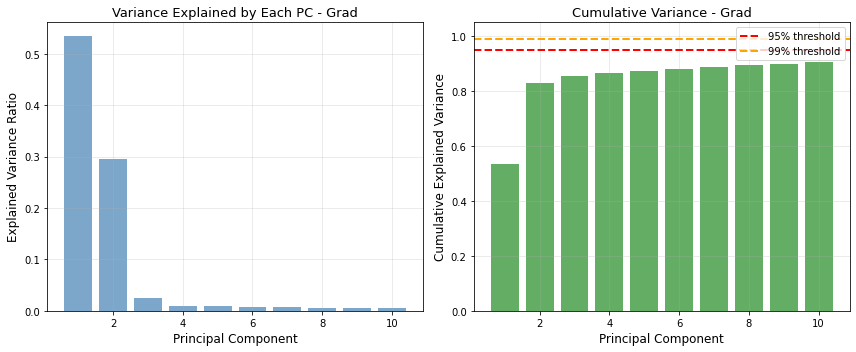

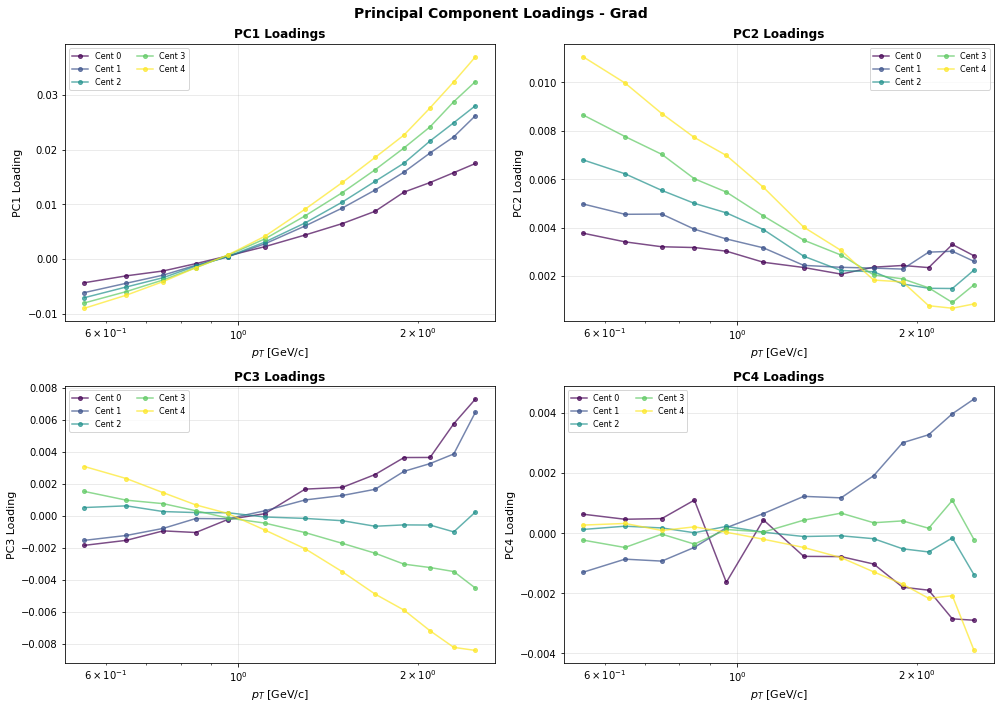

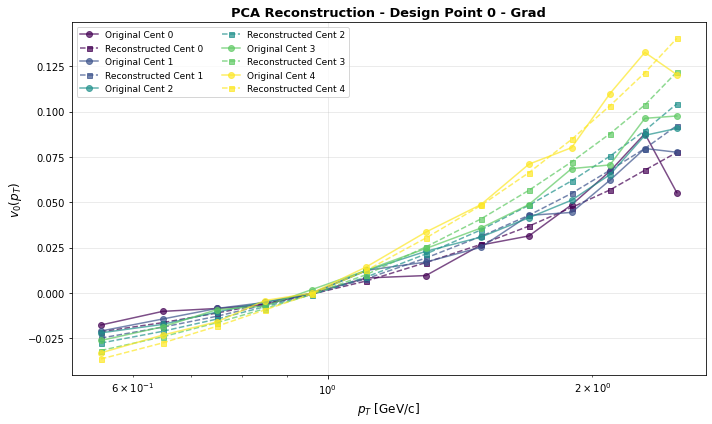


✓ Completed Grad

Processing: CE

1. Loading data...
  ✓ Loaded 500 design points

2. Extracting v0(pT) matrix...
  Data matrix shape: (500, 65)
  Design points: 500
  Observables: 65
  pT bins removed: 80 / 145 (filter = (2.5, inf))
  Maximum possible PCs (min[n_design_points, n_observables]): 65

3. Performing PCA...
  Selected 10 PCs to capture 90.0% variance (max available = 65)
  PC scores shape: (500, 10)
  Explained variance by first 10 PCs: 0.9038

4. Reconstructing data...
  Mean squared reconstruction error: 2.551098e-04

5. Creating plots...


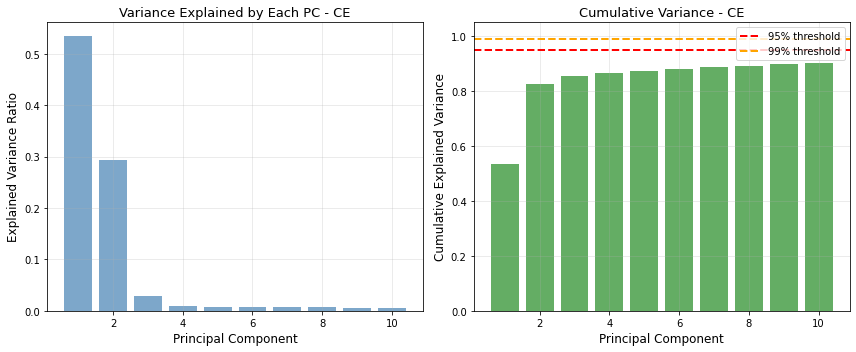

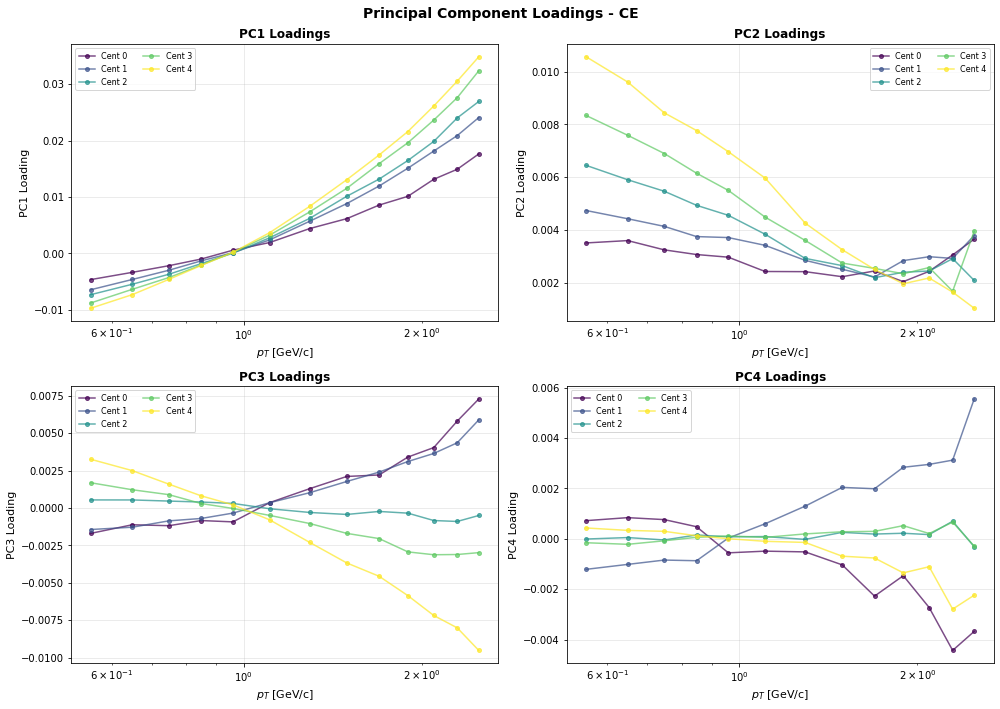

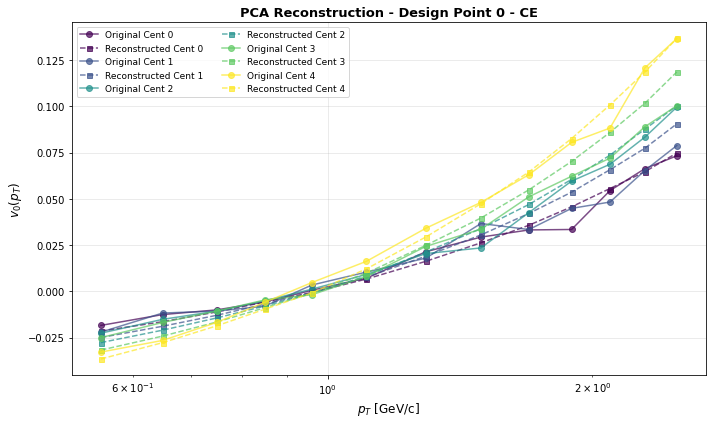


✓ Completed CE

Processing: PTM

1. Loading data...
  ✓ Loaded 500 design points

2. Extracting v0(pT) matrix...
  Data matrix shape: (500, 65)
  Design points: 500
  Observables: 65
  pT bins removed: 80 / 145 (filter = (2.5, inf))
  Maximum possible PCs (min[n_design_points, n_observables]): 65

3. Performing PCA...
  Selected 10 PCs to capture 90.0% variance (max available = 65)
  PC scores shape: (500, 10)
  Explained variance by first 10 PCs: 0.9024

4. Reconstructing data...
  Mean squared reconstruction error: 2.682854e-04

5. Creating plots...


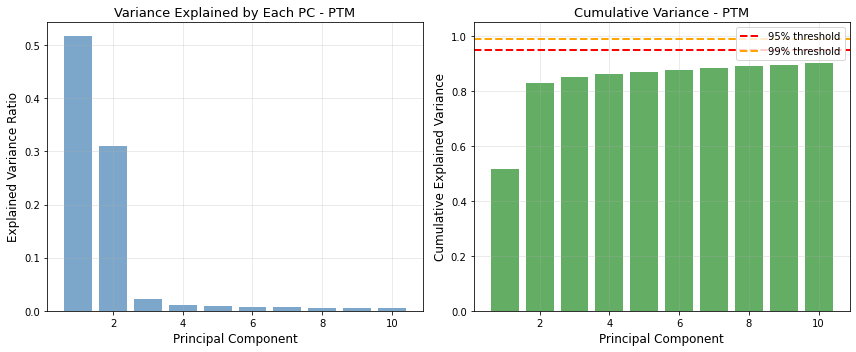

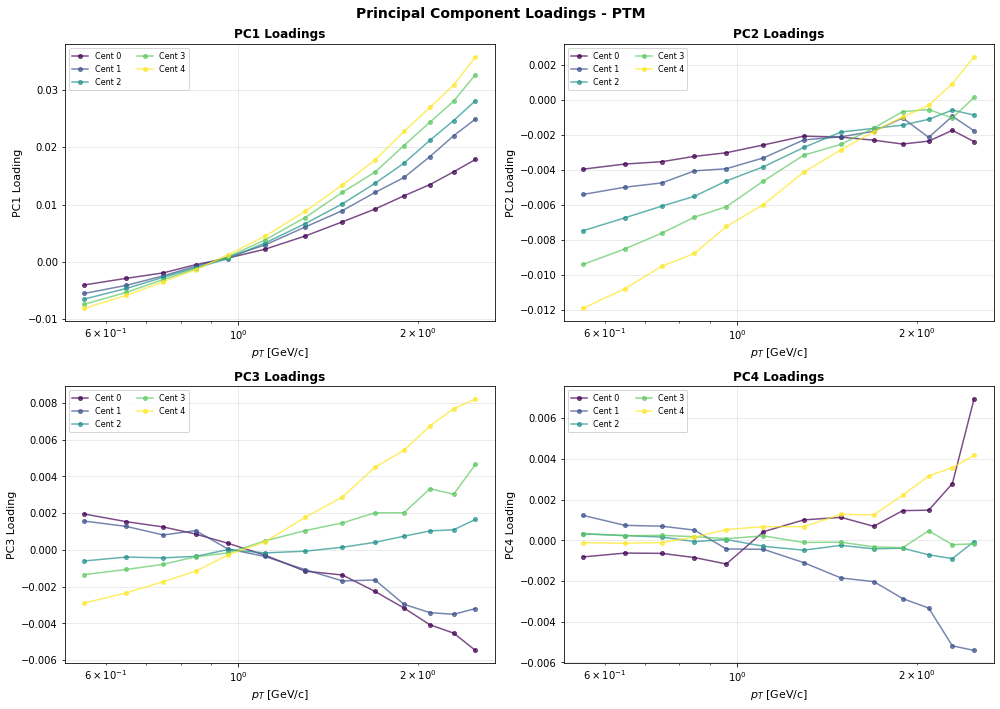

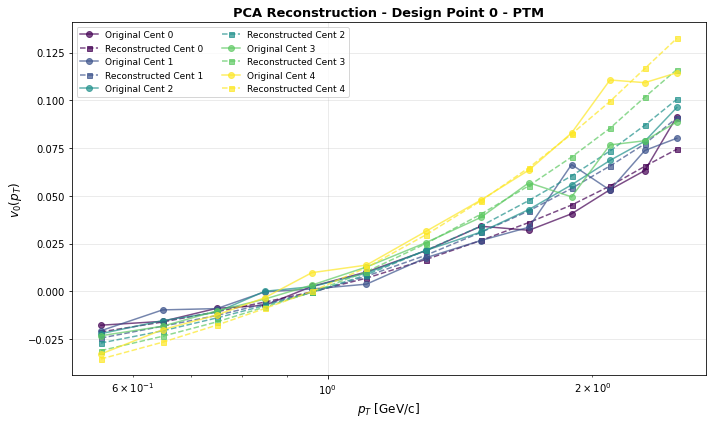


✓ Completed PTM

Processing: PTB

1. Loading data...
  ✓ Loaded 500 design points

2. Extracting v0(pT) matrix...
  Data matrix shape: (500, 65)
  Design points: 500
  Observables: 65
  pT bins removed: 80 / 145 (filter = (2.5, inf))
  Maximum possible PCs (min[n_design_points, n_observables]): 65

3. Performing PCA...
  Selected 11 PCs to capture 90.0% variance (max available = 65)
  PC scores shape: (500, 11)
  Explained variance by first 11 PCs: 0.9033

4. Reconstructing data...
  Mean squared reconstruction error: 3.995645e-04

5. Creating plots...


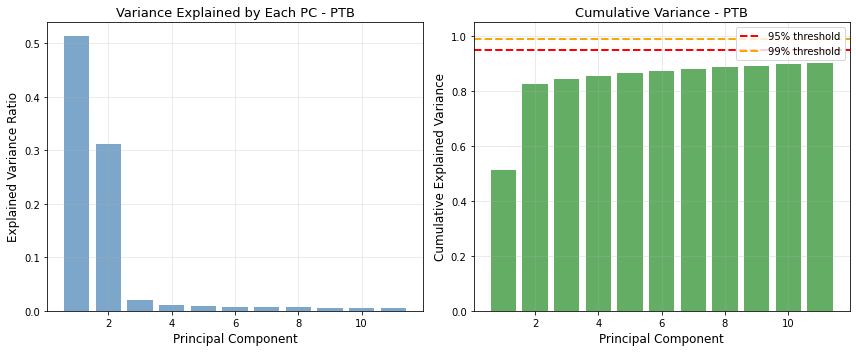

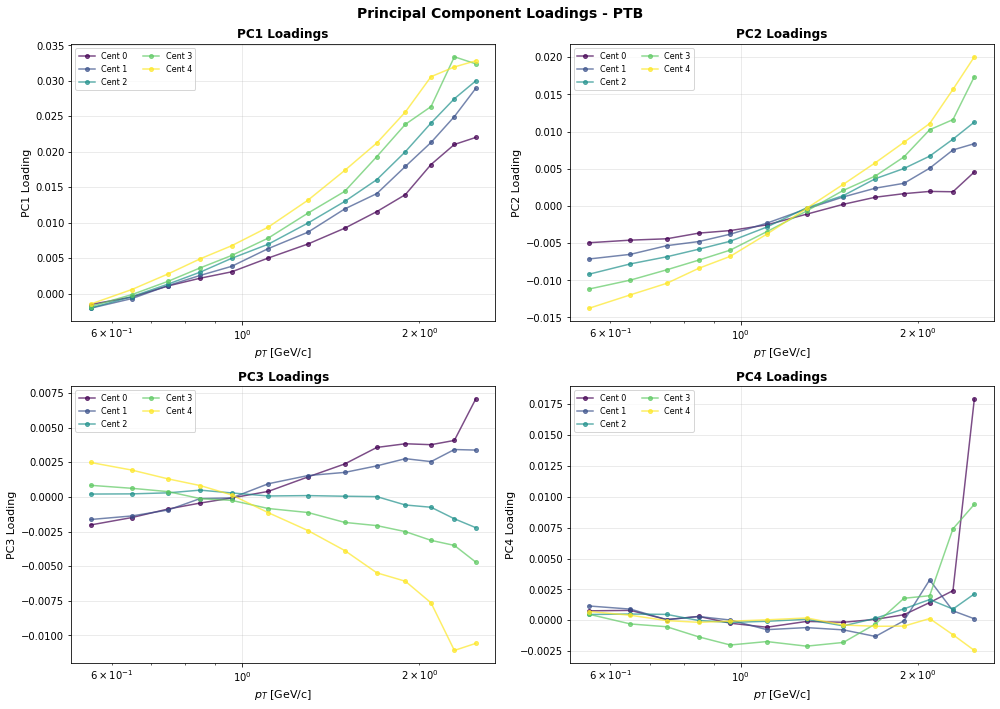

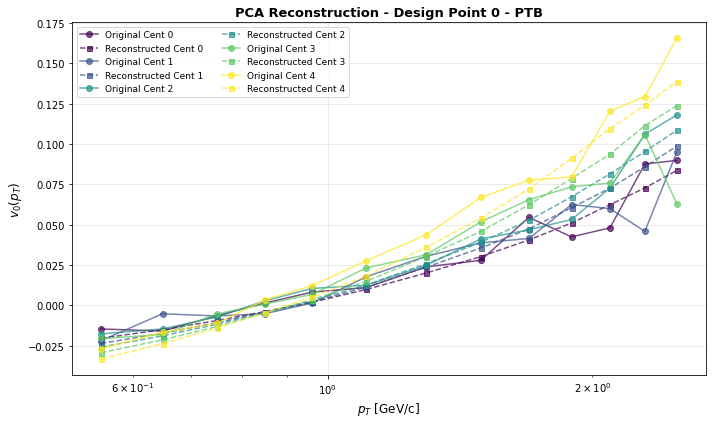


✓ Completed PTB

Creating comparison plots...


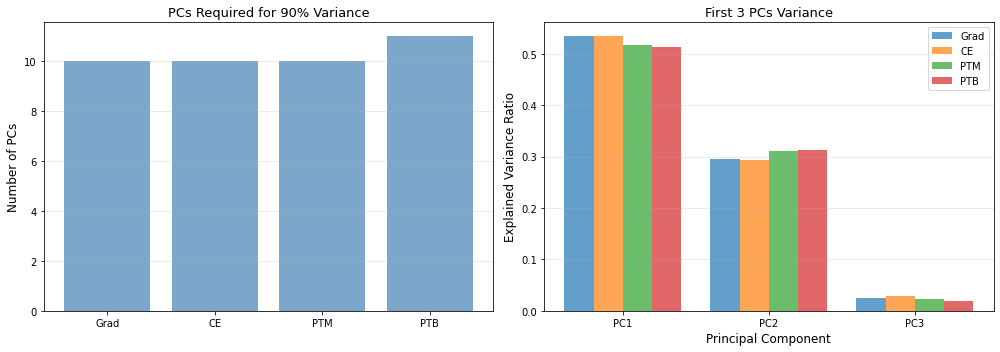


SUMMARY

Grad:
  Design points         : 500
  Observables (after filtering) : 65
  Max possible PCs      : 65
  PCs selected          : 10
  Variance captured     : 0.9049
  Reconstruction error  : 2.758441e-04

CE:
  Design points         : 500
  Observables (after filtering) : 65
  Max possible PCs      : 65
  PCs selected          : 10
  Variance captured     : 0.9038
  Reconstruction error  : 2.551098e-04

PTM:
  Design points         : 500
  Observables (after filtering) : 65
  Max possible PCs      : 65
  PCs selected          : 10
  Variance captured     : 0.9024
  Reconstruction error  : 2.682854e-04

PTB:
  Design points         : 500
  Observables (after filtering) : 65
  Max possible PCs      : 65
  PCs selected          : 11
  Variance captured     : 0.9033
  Reconstruction error  : 3.995645e-04

✓ PCA analysis complete!
Results saved to: pca_results



In [8]:
#!/usr/bin/env python3
"""
Perform PCA on v0(pT) data for all viscous corrections.
Prepares data for emulator training by reducing dimensionality.

Supports removing both centrality bins AND pT bins before PCA.
"""
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import math

# =============================================================================
# CONFIGURATION
# =============================================================================

# Input files for different viscous corrections
VISCOUS_CORRECTIONS = {
    'Grad': 'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_Grad.pkl',
    'CE':   'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_CE.pkl',
    'PTM':  'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_PTM.pkl',
    'PTB':  'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_PTB.pkl'
}

# PCA settings
N_COMPONENTS = None          # If None, determined by variance_threshold
VARIANCE_THRESHOLD = 0.90    # Capture 95% of variance

# Species to analyze
SPECIES = 'charged'

# Centralities to include (None = all available)
CENTRALITIES_TO_INCLUDE = [0, 1, 2, 3, 4]   # e.g. [5, 6] for 50-60%, 60-70%

# -----------------------------------------------------------------------------
# pT BINS TO REMOVE
# -----------------------------------------------------------------------------
# Two supported formats:
#   1) list of integer indices  -> remove these pT-bin indices (same index for
#      every centrality, assumes identical pT binning across centralities)
#         e.g.  PT_BINS_TO_REMOVE = [0, 1, 2]      # drop 3 lowest pT bins
#   2) tuple (pT_low, pT_high) in GeV/c (inclusive) -> remove every pT bin
#      whose pT center falls inside the range
#         e.g.  PT_BINS_TO_REMOVE = (0.0, 0.5)     # drop low-pT region
#                PT_BINS_TO_REMOVE = (2.0, 3.0)     # drop a mid-pT region
#
# Set to None to keep every pT bin (original behaviour).
PT_BINS_TO_REMOVE = (2.5, np.inf)

# Output folder
OUTPUT_FOLDER = 'pca_results'

# =============================================================================
# UTILITY FUNCTIONS
# =============================================================================

def save_fig(fig, filename, folder):
    """Save figure to folder"""
    Path(folder).mkdir(parents=True, exist_ok=True)
    filepath = Path(folder) / filename
    fig.savefig(filepath, dpi=300, bbox_inches='tight')
    print(f"  Saved: {filepath}")


def _build_pt_keep_mask(pt_centers, pt_bins_to_remove):
    """
    Build a boolean mask over pT bins for a single centrality/species.

    pt_bins_to_remove:
        None                        -> keep all
        list/tuple of ints          -> remove those indices
        tuple (lo, hi)              -> remove bins with pt_center in [lo, hi]
    """
    pt_centers = np.asarray(pt_centers)
    keep = np.ones(len(pt_centers), dtype=bool)

    if pt_bins_to_remove is None:
        return keep

    # Range form: (lo, hi)
    if (isinstance(pt_bins_to_remove, tuple)
            and len(pt_bins_to_remove) == 2
            and all(isinstance(x, (int, float, np.floating, np.integer))
                    for x in pt_bins_to_remove)):
        lo, hi = pt_bins_to_remove
        keep &= ~((pt_centers >= lo) & (pt_centers <= hi))
        return keep

    # Index form: list of ints
    if isinstance(pt_bins_to_remove, (list, tuple, np.ndarray)):
        idxs = [int(i) for i in pt_bins_to_remove
                if 0 <= int(i) < len(pt_centers)]
        if idxs:
            keep[idxs] = False
        return keep

    raise ValueError(f"Unsupported PT_BINS_TO_REMOVE format: {pt_bins_to_remove!r}")


# =============================================================================
# DATA LOADING
# =============================================================================

def load_results(filename):
    """Load pickle file with v0(pT) results"""
    if not Path(filename).exists():
        print(f"Warning: File '{filename}' not found!")
        return None
    with open(filename, 'rb') as f:
        results = pickle.load(f)
    return results


def extract_v0pt_matrix(results, species, centralities=None, pt_bins_to_remove=None):
    """
    Extract v0(pT) data as a matrix for PCA, optionally dropping pT bins.

    Parameters
    ----------
    results : list
        List of per-design-point result dicts.
    species : str
        Species key (e.g. 'charged').
    centralities : list or None
        Centrality indices to keep (None = all).
    pt_bins_to_remove : None | list[int] | tuple(float, float)
        pT bins to remove, either by index or by pT range in GeV.

    Returns
    -------
    Y_data : (n_design_points, n_observables) ndarray
    design_point_ids : (n_design_points,) ndarray
    observable_labels : list of (cent_idx, pt_center)
    """
    if results is None or len(results) == 0:
        return None, None, None

    first_result = results[0]
    if centralities is None:
        cent_indices = sorted(first_result['centrality_data'].keys())
    else:
        cent_indices = centralities

    # ---------------------------------------------------------------------
    # Build observable labels once, using the first design point.
    # This guarantees a consistent ordering across all design points.
    # ---------------------------------------------------------------------
    observable_labels = []
    for cent_idx in cent_indices:
        if cent_idx not in first_result['centrality_data']:
            continue
        cent_data = first_result['centrality_data'][cent_idx]
        if species not in cent_data:
            continue

        pt_centers = np.asarray(cent_data[species]['pt_centers'])
        keep = _build_pt_keep_mask(pt_centers, pt_bins_to_remove)
        for pt in pt_centers[keep]:
            observable_labels.append((cent_idx, float(pt)))

    n_obs = len(observable_labels)
    if n_obs == 0:
        print("  Warning: no observables left after filtering!")
        return None, None, None

    # ---------------------------------------------------------------------
    # Fill the data matrix
    # ---------------------------------------------------------------------
    Y_data = []
    design_point_ids = []

    for result in results:
        v0pt_values = []

        for cent_idx in cent_indices:
            if cent_idx not in result['centrality_data']:
                continue
            cent_data = result['centrality_data'][cent_idx]
            if species not in cent_data:
                continue

            sp = cent_data[species]
            v0pt = np.asarray(sp['v0pT'])
            pt_centers = np.asarray(sp['pt_centers'])
            keep = _build_pt_keep_mask(pt_centers, pt_bins_to_remove)
            v0pt_values.extend(v0pt[keep])

        if len(v0pt_values) == n_obs:
            Y_data.append(v0pt_values)
            design_point_ids.append(result['design_point'])
        else:
            print(f"  Warning: design point {result.get('design_point', '?')} "
                  f"has {len(v0pt_values)} values (expected {n_obs}); skipping")

    Y_data = np.array(Y_data)
    design_point_ids = np.array(design_point_ids)

    print(f"  Data matrix shape: {Y_data.shape}")
    print(f"  Design points: {len(design_point_ids)}")
    print(f"  Observables: {Y_data.shape[1]}")

    # --- Report how many pT bins were actually removed ---
    if pt_bins_to_remove is not None:
        n_removed = 0
        n_total = 0
        for cent_idx in cent_indices:
            if (cent_idx in first_result['centrality_data']
                    and species in first_result['centrality_data'][cent_idx]):
                pt_centers = first_result['centrality_data'][cent_idx][species]['pt_centers']
                keep = _build_pt_keep_mask(pt_centers, pt_bins_to_remove)
                n_removed += int((~keep).sum())
                n_total += len(pt_centers)
        print(f"  pT bins removed: {n_removed} / {n_total} "
              f"(filter = {pt_bins_to_remove})")

    # --- Report the hard ceiling on number of PCs ---
    max_pcs = min(Y_data.shape[0], Y_data.shape[1])
    print(f"  Maximum possible PCs (min[n_design_points, n_observables]): {max_pcs}")

    return Y_data, design_point_ids, observable_labels


# =============================================================================
# PCA FUNCTIONS
# =============================================================================

def perform_pca_on_v0(Y_data, n_components=10, variance_threshold=0.99):
    """
    Perform PCA on v0 data matrix.

    The number of retained components is capped at
    min(n_design_points, n_observables).
    """
    # Standardize data
    scaler = StandardScaler()
    Y_scaled = scaler.fit_transform(Y_data)

    # SVD decomposition
    u, s, vh = np.linalg.svd(Y_scaled, full_matrices=False)
    max_pcs = len(s)   # = min(n_samples, n_observables)

    # Determine number of components
    if n_components is None:
        explained_var_ratio = (s ** 2) / np.sum(s ** 2)
        cumulative_var = np.cumsum(explained_var_ratio)
        n_components = int(np.searchsorted(cumulative_var, variance_threshold) + 1)
        n_components = min(n_components, max_pcs)
        print(f"  Selected {n_components} PCs to capture "
              f"{variance_threshold * 100:.1f}% variance "
              f"(max available = {max_pcs})")
    else:
        if n_components > max_pcs:
            print(f"  Requested {n_components} PCs, but only {max_pcs} available. "
                  f"Capping at {max_pcs}.")
            n_components = max_pcs

    # PC scores (whitened)
    pc_scores = u[:, :n_components] * math.sqrt(u.shape[0] - 1)

    # Inverse transformation matrix
    inverse_tf_matrix = (np.diag(s[:n_components]) @ vh[:n_components, :] *
                         scaler.scale_.reshape(1, -1) / math.sqrt(u.shape[0] - 1))

    # Explained variance
    explained_variance = (s[:n_components] ** 2) / np.sum(s ** 2)

    print(f"  PC scores shape: {pc_scores.shape}")
    print(f"  Explained variance by first {n_components} PCs: "
          f"{np.sum(explained_variance):.4f}")

    return scaler, pc_scores, inverse_tf_matrix, explained_variance


def reconstruct_from_pca(pc_scores, inverse_tf_matrix, scaler):
    """Reconstruct original data from PC scores."""
    Y_scaled = pc_scores @ inverse_tf_matrix / math.sqrt(pc_scores.shape[0] - 1)
    Y_reconstructed = scaler.inverse_transform(Y_scaled)
    return Y_reconstructed


# =============================================================================
# PLOTTING FUNCTIONS
# =============================================================================

def plot_pca_variance(explained_variance, correction_name, save_folder):
    """Plot explained variance by principal components"""
    n_pc = len(explained_variance)
    cumulative = np.cumsum(explained_variance)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.bar(np.arange(1, n_pc + 1), explained_variance, color='steelblue', alpha=0.7)
    ax1.set_xlabel("Principal Component", fontsize=12)
    ax1.set_ylabel("Explained Variance Ratio", fontsize=12)
    ax1.set_title(f"Variance Explained by Each PC - {correction_name}", fontsize=13)
    ax1.grid(True, alpha=0.3)

    ax2.bar(np.arange(1, n_pc + 1), cumulative, color='forestgreen', alpha=0.7)
    ax2.axhline(0.95, color='red', linestyle='--', linewidth=2, label='95% threshold')
    ax2.axhline(0.99, color='orange', linestyle='--', linewidth=2, label='99% threshold')
    ax2.set_xlabel("Principal Component", fontsize=12)
    ax2.set_ylabel("Cumulative Explained Variance", fontsize=12)
    ax2.set_title(f"Cumulative Variance - {correction_name}", fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(0, 1.05)

    plt.tight_layout()
    return fig


def plot_pc_loadings(inverse_tf_matrix, observable_labels, correction_name,
                     save_folder, n_pc_to_plot=4):
    """Plot PC loadings to understand what each PC represents"""
    n_pc = min(n_pc_to_plot, inverse_tf_matrix.shape[0])

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for i in range(n_pc):
        ax = axes[i]
        loadings = inverse_tf_matrix[i, :]

        centralities = sorted(set(label[0] for label in observable_labels))
        colors = plt.cm.viridis(np.linspace(0, 1, len(centralities)))

        for cent_idx, color in zip(centralities, colors):
            cent_mask = [label[0] == cent_idx for label in observable_labels]
            pt_values = [label[1] for label, mask in
                         zip(observable_labels, cent_mask) if mask]
            cent_loadings = loadings[cent_mask]
            ax.plot(pt_values, cent_loadings, 'o-', color=color,
                    label=f'Cent {cent_idx}', alpha=0.7, markersize=4)

        ax.set_xlabel(r'$p_T$ [GeV/c]', fontsize=11)
        ax.set_ylabel(f'PC{i + 1} Loading', fontsize=11)
        ax.set_title(f'PC{i + 1} Loadings', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, ncol=2)
        ax.set_xscale('log')

    # Hide unused axes if fewer than 4 PCs
    for j in range(n_pc, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f'Principal Component Loadings - {correction_name}',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return fig


def plot_reconstruction_comparison(Y_data, Y_reconstructed, design_point_idx,
                                   observable_labels, correction_name, save_folder):
    """Compare original vs reconstructed data for a sample design point"""
    fig, ax = plt.subplots(figsize=(10, 6))

    original = Y_data[design_point_idx, :]
    reconstructed = Y_reconstructed[design_point_idx, :]

    centralities = sorted(set(label[0] for label in observable_labels))
    colors = plt.cm.viridis(np.linspace(0, 1, len(centralities)))

    for cent_idx, color in zip(centralities, colors):
        cent_mask = [label[0] == cent_idx for label in observable_labels]
        pt_values = [label[1] for label, mask in
                     zip(observable_labels, cent_mask) if mask]
        orig_vals = original[cent_mask]
        recon_vals = reconstructed[cent_mask]

        ax.plot(pt_values, orig_vals, 'o-', color=color,
                label=f'Original Cent {cent_idx}', alpha=0.7, markersize=6)
        ax.plot(pt_values, recon_vals, 's--', color=color,
                label=f'Reconstructed Cent {cent_idx}', alpha=0.7, markersize=5)

    ax.set_xlabel(r'$p_T$ [GeV/c]', fontsize=12)
    ax.set_ylabel(r'$v_0(p_T)$', fontsize=12)
    ax.set_title(f'PCA Reconstruction - Design Point {design_point_idx} - '
                 f'{correction_name}', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, ncol=2)
    ax.set_xscale('log')

    plt.tight_layout()
    plt.show()
    return fig


def compare_pca_across_corrections(pca_results_dict, save_folder):
    """Compare PCA results across different viscous corrections"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    corrections = list(pca_results_dict.keys())
    n_pcs = [pca_results_dict[corr]['n_components'] for corr in corrections]

    ax1 = axes[0]
    ax1.bar(corrections, n_pcs, color='steelblue', alpha=0.7)
    ax1.set_ylabel('Number of PCs', fontsize=12)
    ax1.set_title(f'PCs Required for {VARIANCE_THRESHOLD * 100:.0f}% Variance',
                  fontsize=13)
    ax1.grid(True, alpha=0.3, axis='y')

    ax2 = axes[1]
    for i, corr in enumerate(corrections):
        exp_var = pca_results_dict[corr]['explained_variance'][:3]
        x = np.arange(1, len(exp_var) + 1) + i * 0.2
        ax2.bar(x, exp_var, width=0.2, label=corr, alpha=0.7)

    ax2.set_xlabel('Principal Component', fontsize=12)
    ax2.set_ylabel('Explained Variance Ratio', fontsize=12)
    ax2.set_title('First 3 PCs Variance', fontsize=13)
    ax2.set_xticks([1.3, 2.3, 3.3])
    ax2.set_xticklabels(['PC1', 'PC2', 'PC3'])
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.show()
    return fig


# =============================================================================
# MAIN EXECUTION
# =============================================================================

if __name__ == "__main__":
    print("=" * 80)
    print("PCA ANALYSIS FOR v0(pT) EMULATOR TRAINING")
    print("=" * 80)
    print(f"Centralities included : {CENTRALITIES_TO_INCLUDE}")
    print(f"pT bins to remove     : {PT_BINS_TO_REMOVE}")
    print(f"Variance threshold    : {VARIANCE_THRESHOLD}")

    Path(OUTPUT_FOLDER).mkdir(parents=True, exist_ok=True)

    pca_results_dict = {}

    for corr_name, filepath in VISCOUS_CORRECTIONS.items():
        print(f"\n{'=' * 80}")
        print(f"Processing: {corr_name}")
        print(f"{'=' * 80}")

        # 1. Load
        print("\n1. Loading data...")
        results = load_results(filepath)
        if results is None:
            print(f"  ✗ Skipping {corr_name} - file not found")
            continue
        print(f"  ✓ Loaded {len(results)} design points")

        # 2. Extract (with centrality AND pT filtering)
        print("\n2. Extracting v0(pT) matrix...")
        Y_data, design_point_ids, observable_labels = extract_v0pt_matrix(
            results, SPECIES, CENTRALITIES_TO_INCLUDE, PT_BINS_TO_REMOVE
        )
        if Y_data is None:
            print(f"  ✗ Skipping {corr_name} - no data extracted")
            continue

        # 3. PCA
        print("\n3. Performing PCA...")
        scaler, pc_scores, inverse_tf_matrix, explained_variance = perform_pca_on_v0(
            Y_data, N_COMPONENTS, VARIANCE_THRESHOLD
        )
        n_components = pc_scores.shape[1]

        # 4. Reconstruction check
        print("\n4. Reconstructing data...")
        Y_reconstructed = reconstruct_from_pca(pc_scores, inverse_tf_matrix, scaler)
        reconstruction_error = np.mean((Y_data - Y_reconstructed) ** 2)
        print(f"  Mean squared reconstruction error: {reconstruction_error:.6e}")

        pca_results_dict[corr_name] = {
            'Y_data': Y_data,
            'design_point_ids': design_point_ids,
            'observable_labels': observable_labels,
            'scaler': scaler,
            'pc_scores': pc_scores,
            'inverse_tf_matrix': inverse_tf_matrix,
            'explained_variance': explained_variance,
            'n_components': n_components,
            'reconstruction_error': reconstruction_error,
        }

        # 5. Plots
        print("\n5. Creating plots...")
        plot_pca_variance(explained_variance, corr_name, OUTPUT_FOLDER)
        plot_pc_loadings(inverse_tf_matrix, observable_labels, corr_name, OUTPUT_FOLDER)
        plot_reconstruction_comparison(Y_data, Y_reconstructed, 0,
                                       observable_labels, corr_name, OUTPUT_FOLDER)

        print(f"\n✓ Completed {corr_name}")

    # Cross-correction comparison
    if len(pca_results_dict) > 1:
        print(f"\n{'=' * 80}")
        print("Creating comparison plots...")
        print(f"{'=' * 80}")
        compare_pca_across_corrections(pca_results_dict, OUTPUT_FOLDER)

    # Summary
    print(f"\n{'=' * 80}")
    print("SUMMARY")
    print(f"{'=' * 80}")
    for corr_name, res in pca_results_dict.items():
        n_obs = res['Y_data'].shape[1]
        n_dp = len(res['design_point_ids'])
        max_pcs = min(n_dp, n_obs)
        print(f"\n{corr_name}:")
        print(f"  Design points         : {n_dp}")
        print(f"  Observables (after filtering) : {n_obs}")
        print(f"  Max possible PCs      : {max_pcs}")
        print(f"  PCs selected          : {res['n_components']}")
        print(f"  Variance captured     : {np.sum(res['explained_variance']):.4f}")
        print(f"  Reconstruction error  : {res['reconstruction_error']:.6e}")

    print(f"\n{'=' * 80}")
    print("✓ PCA analysis complete!")
    print(f"Results saved to: {OUTPUT_FOLDER}")
    print(f"{'=' * 80}\n")

### PCA $v_0(p_T)/v_0$

PCA ANALYSIS FOR v0(pT)/v0 EMULATOR TRAINING
Centralities included : [0, 1, 2, 3, 4]
pT bins to remove     : (2.5, inf)
Variance threshold    : 0.9

Processing: Grad

1. Loading data...
  ✓ Loaded 500 design points

2. Extracting v0(pT)/v0 matrix...
  Ratio source: computed
  Data matrix shape: (500, 65)
  Design points: 500
  Observables: 65
  pT bins removed: 80 / 145 (filter = (2.5, inf))
  Maximum possible PCs (min[n_design_points, n_observables]): 65

3. Performing PCA...
  Selected 25 PCs to capture 90.0% variance (max available = 65)
  PC scores shape: (500, 25)
  Explained variance by first 25 PCs: 0.9032

4. Reconstructing data...
  Mean squared reconstruction error: 1.193437e+00

5. Creating plots...


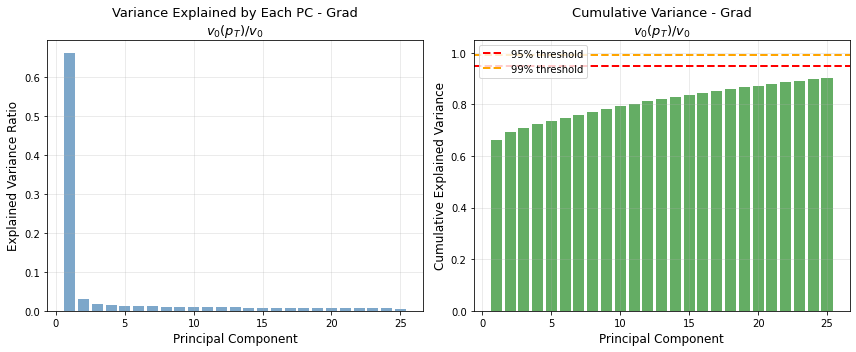

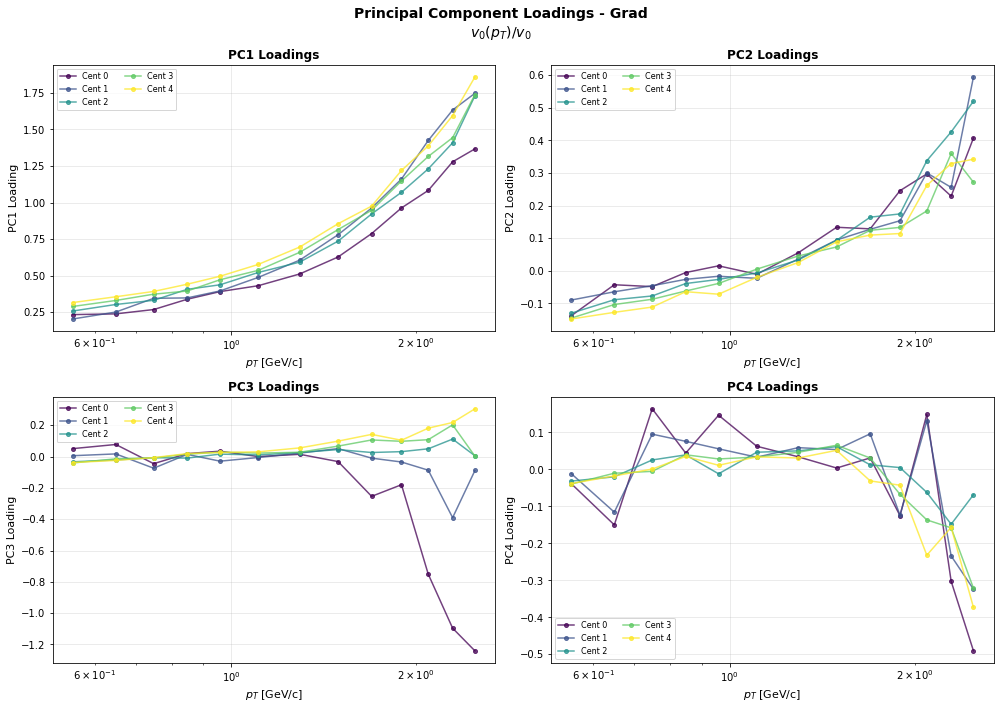

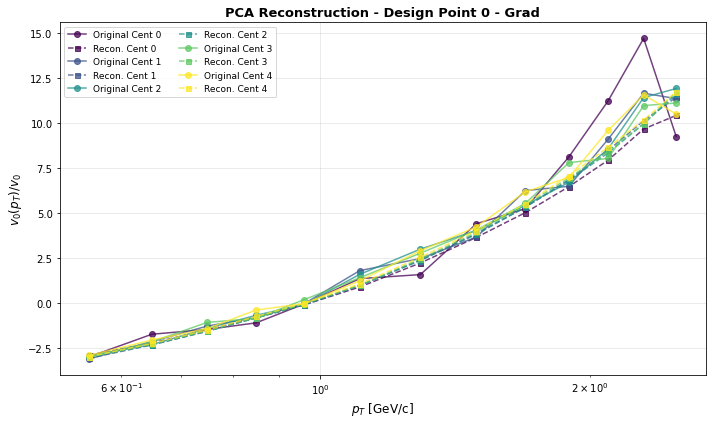


✓ Completed Grad

Processing: CE

1. Loading data...
  ✓ Loaded 500 design points

2. Extracting v0(pT)/v0 matrix...
  Ratio source: computed
  Data matrix shape: (500, 65)
  Design points: 500
  Observables: 65
  pT bins removed: 80 / 145 (filter = (2.5, inf))
  Maximum possible PCs (min[n_design_points, n_observables]): 65

3. Performing PCA...
  Selected 26 PCs to capture 90.0% variance (max available = 65)
  PC scores shape: (500, 26)
  Explained variance by first 26 PCs: 0.9037

4. Reconstructing data...
  Mean squared reconstruction error: 1.111754e+00

5. Creating plots...


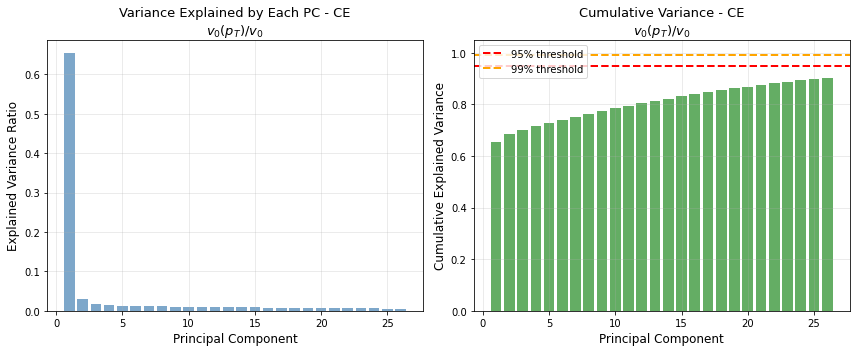

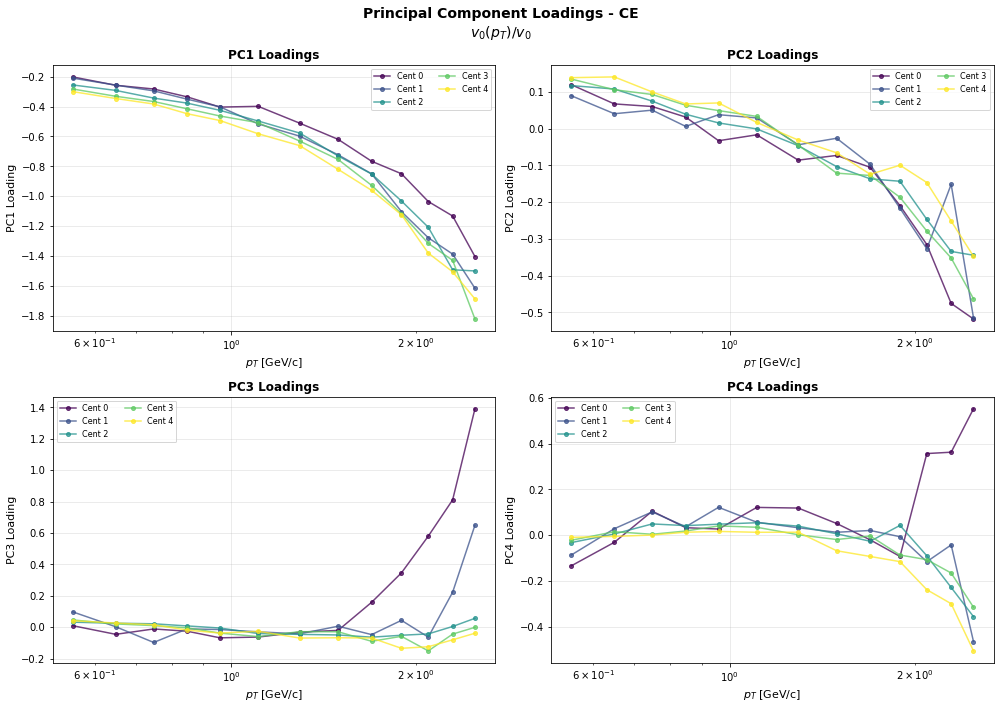

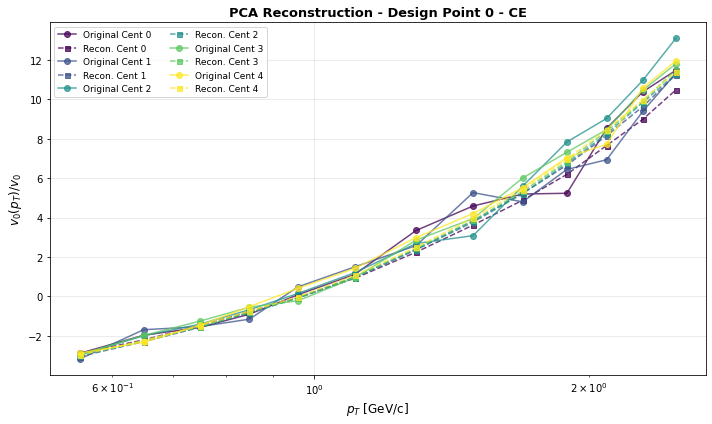


✓ Completed CE

Processing: PTM

1. Loading data...
  ✓ Loaded 500 design points

2. Extracting v0(pT)/v0 matrix...
  Ratio source: computed
  Data matrix shape: (500, 65)
  Design points: 500
  Observables: 65
  pT bins removed: 80 / 145 (filter = (2.5, inf))
  Maximum possible PCs (min[n_design_points, n_observables]): 65

3. Performing PCA...
  Selected 24 PCs to capture 90.0% variance (max available = 65)
  PC scores shape: (500, 24)
  Explained variance by first 24 PCs: 0.9015

4. Reconstructing data...
  Mean squared reconstruction error: 1.301299e+00

5. Creating plots...


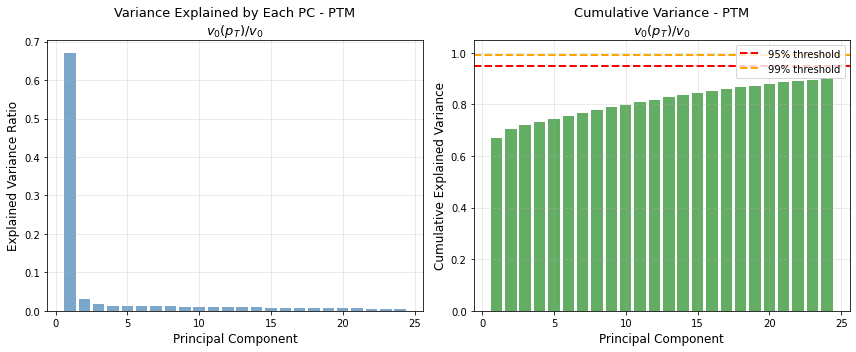

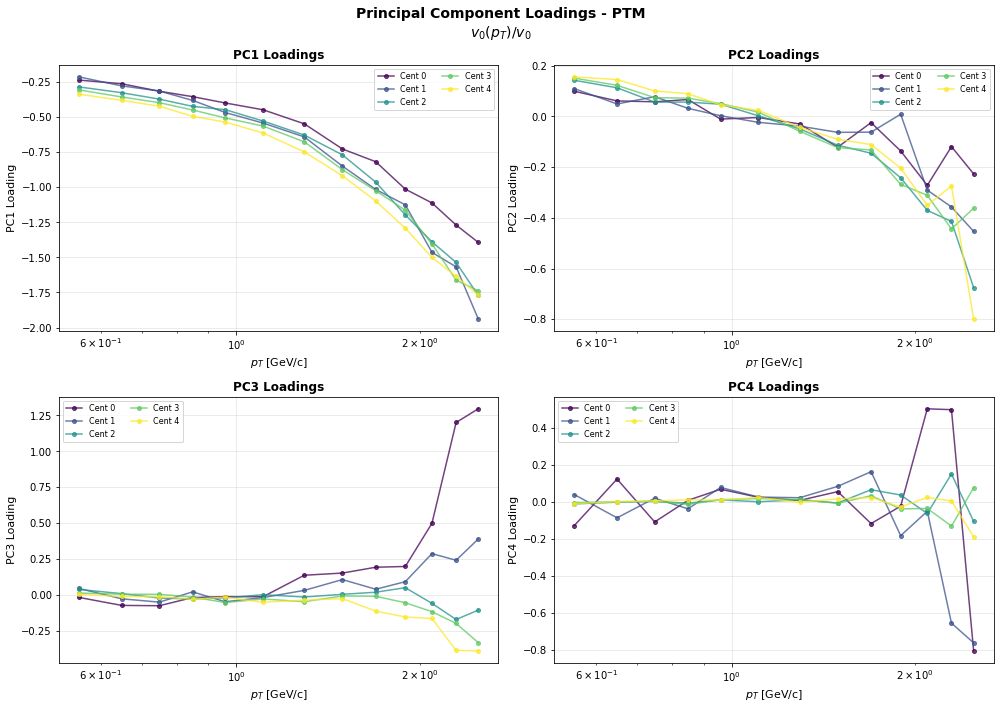

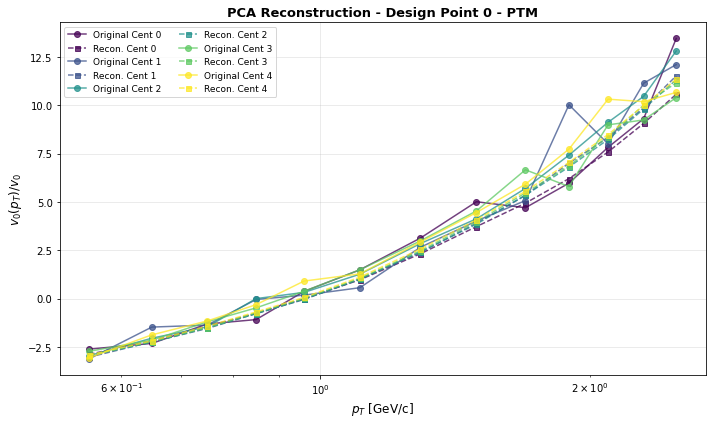


✓ Completed PTM

Processing: PTB

1. Loading data...
  ✓ Loaded 500 design points

2. Extracting v0(pT)/v0 matrix...
  Ratio source: computed
  Data matrix shape: (500, 65)
  Design points: 500
  Observables: 65
  pT bins removed: 80 / 145 (filter = (2.5, inf))
  Maximum possible PCs (min[n_design_points, n_observables]): 65

3. Performing PCA...
  Selected 21 PCs to capture 90.0% variance (max available = 65)
  PC scores shape: (500, 21)
  Explained variance by first 21 PCs: 0.9007

4. Reconstructing data...
  Mean squared reconstruction error: 2.320554e+00

5. Creating plots...


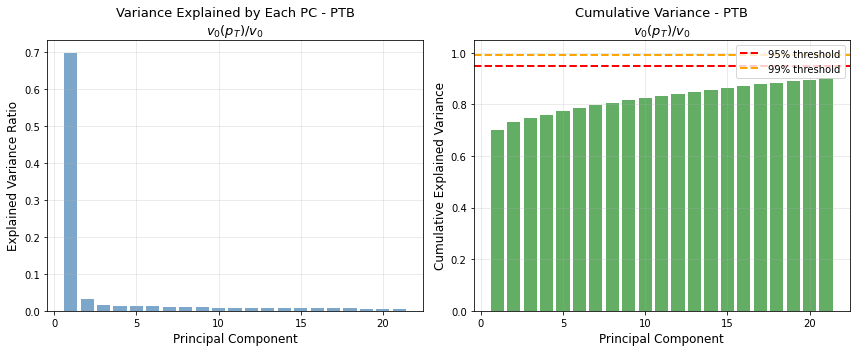

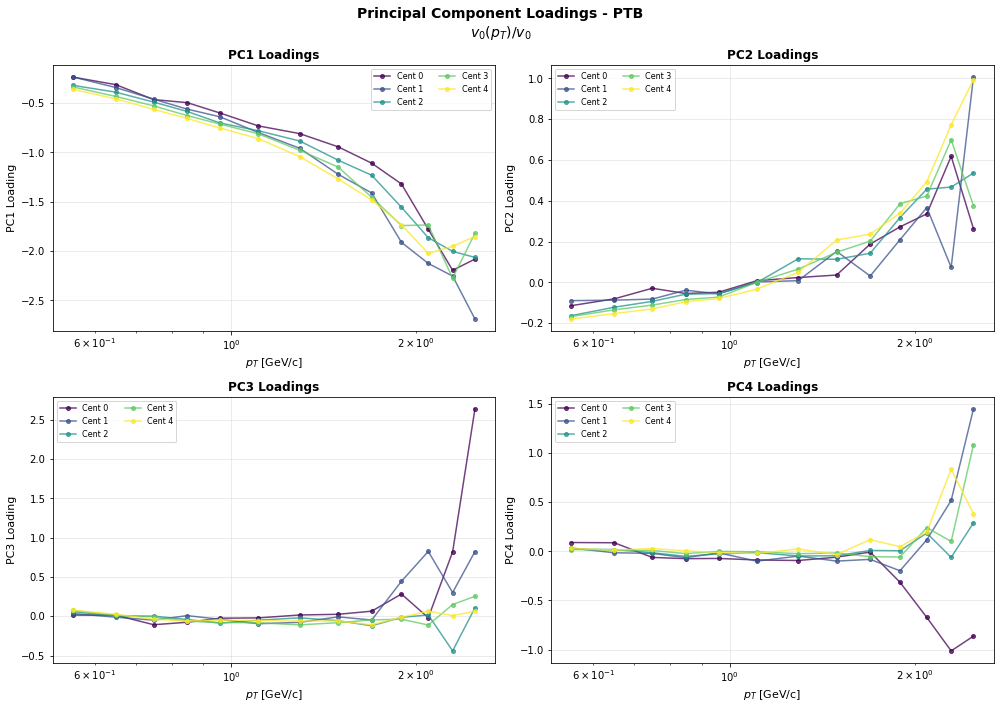

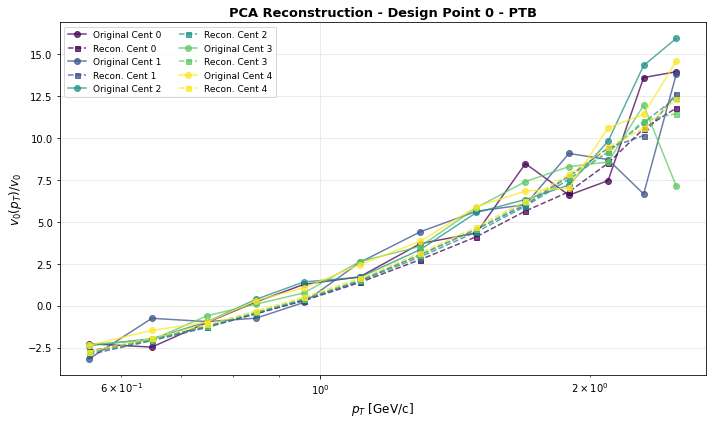


✓ Completed PTB

Creating comparison plots...


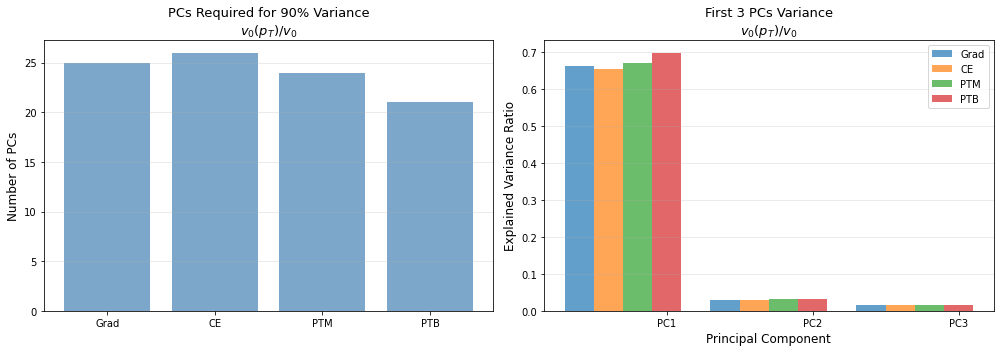


SUMMARY - v0(pT)/v0

Grad:
  Design points                : 500
  Observables (after filtering): 65
  Max possible PCs             : 65
  PCs selected                 : 25
  Variance captured            : 0.9032
  Reconstruction error         : 1.193437e+00

CE:
  Design points                : 500
  Observables (after filtering): 65
  Max possible PCs             : 65
  PCs selected                 : 26
  Variance captured            : 0.9037
  Reconstruction error         : 1.111754e+00

PTM:
  Design points                : 500
  Observables (after filtering): 65
  Max possible PCs             : 65
  PCs selected                 : 24
  Variance captured            : 0.9015
  Reconstruction error         : 1.301299e+00

PTB:
  Design points                : 500
  Observables (after filtering): 65
  Max possible PCs             : 65
  PCs selected                 : 21
  Variance captured            : 0.9007
  Reconstruction error         : 2.320554e+00

✓ PCA analysis for v0(pT)/v0 c

In [11]:
#!/usr/bin/env python3
"""
Perform PCA on v0(pT)/v0 (ratio) data for all viscous corrections.
Prepares data for emulator training by reducing dimensionality.

The ratio is a pT-differential observable, so the pipeline mirrors the
v0(pT) script: centrality filtering + pT-bin filtering + variance-based
PC truncation.
"""
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import math

# =============================================================================
# CONFIGURATION
# =============================================================================

VISCOUS_CORRECTIONS = {
    'Grad': 'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_Grad.pkl',
    'CE':   'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_CE.pkl',
    'PTM':  'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_PTM.pkl',
    'PTB':  'design_points_data/differential_radial_flow/v0pt_design_points_results_Pb_Pb_2760_PTB.pkl',
}

# PCA settings
N_COMPONENTS = None          # If None, determined by VARIANCE_THRESHOLD
VARIANCE_THRESHOLD = 0.90    # Capture 95% of variance

# Species to analyze
SPECIES = 'charged'

# Centralities to include (None = all available)
CENTRALITIES_TO_INCLUDE = [0,1,2,3,4]   # e.g. [0, 1, 2, 3] for 0-10..30-40%

# -----------------------------------------------------------------------------
# pT BINS TO REMOVE
# -----------------------------------------------------------------------------
#   1) list of ints                -> remove those pT-bin indices
#   2) tuple (pT_low, pT_high)     -> remove bins with pt_center in [lo, hi]
#   3) 'top:N' / 'bottom:N'        -> remove the N largest/smallest pT bins
#   4) None                        -> keep everything
PT_BINS_TO_REMOVE = (2.5, np.inf)

# Output folder
OUTPUT_FOLDER = 'pca_results_ratio'

# =============================================================================
# UTILITY FUNCTIONS
# =============================================================================

def save_fig(fig, filename, folder):
    Path(folder).mkdir(parents=True, exist_ok=True)
    filepath = Path(folder) / filename
    fig.savefig(filepath, dpi=300, bbox_inches='tight')
    print(f"  Saved: {filepath}")


def _build_pt_keep_mask(pt_centers, pt_bins_to_remove):
    """Boolean keep-mask over pT bins (see config comment for formats)."""
    pt_centers = np.asarray(pt_centers)
    n = len(pt_centers)
    keep = np.ones(n, dtype=bool)

    if pt_bins_to_remove is None:
        return keep

    # 'top:N' / 'bottom:N'
    if isinstance(pt_bins_to_remove, str):
        kind, _, n_str = pt_bins_to_remove.partition(':')
        N = int(n_str)
        order = np.argsort(pt_centers)
        if kind == 'top':
            keep[order[-N:]] = False
        elif kind == 'bottom':
            keep[order[:N]] = False
        else:
            raise ValueError(f"Unknown string form: {pt_bins_to_remove!r}")
        return keep

    # (lo, hi) range
    if (isinstance(pt_bins_to_remove, tuple)
            and len(pt_bins_to_remove) == 2
            and all(isinstance(x, (int, float, np.floating, np.integer))
                    for x in pt_bins_to_remove)):
        lo, hi = pt_bins_to_remove
        keep &= ~((pt_centers >= lo) & (pt_centers <= hi))
        return keep

    # Index list (negatives allowed)
    if isinstance(pt_bins_to_remove, (list, tuple, np.ndarray)):
        for i in pt_bins_to_remove:
            i = int(i)
            if -n <= i < n:
                keep[i % n] = False
        return keep

    raise ValueError(f"Unsupported PT_BINS_TO_REMOVE format: {pt_bins_to_remove!r}")


# =============================================================================
# DATA LOADING
# =============================================================================

def load_results(filename):
    if not Path(filename).exists():
        print(f"Warning: File '{filename}' not found!")
        return None
    with open(filename, 'rb') as f:
        results = pickle.load(f)
    return results


# Candidate keys that could hold a pre-computed ratio in the pickle
_RATIO_KEYS = ('v0pT_over_v0', 'v0pT/v0', 'v0pt_over_v0', 'ratio',
               'v0pT_ratio', 'v0pt_ratio')


def _get_ratio(sp_dict):
    """
    Return the v0(pT)/v0 vector for a single (design point, centrality, species).

    Prefers a pre-computed key if present; otherwise computes it as
    v0pT / v0_global (element-wise).
    """
    # 1. Pre-computed ratio?
    for key in _RATIO_KEYS:
        if key in sp_dict:
            return np.asarray(sp_dict[key], dtype=float), 'stored'

    # 2. Compute from v0pT and v0_global
    if 'v0pT' in sp_dict and 'v0_global' in sp_dict:
        v0pt = np.asarray(sp_dict['v0pT'], dtype=float)
        v0g = float(sp_dict['v0_global'])
        with np.errstate(divide='ignore', invalid='ignore'):
            ratio = v0pt / v0g if v0g != 0.0 else np.full_like(v0pt, np.nan)
        return ratio, 'computed'

    raise KeyError(
        "Could not find a ratio in the pickle. Expected one of "
        f"{_RATIO_KEYS} or both 'v0pT' and 'v0_global'."
    )


def extract_ratio_matrix(results, species, centralities=None, pt_bins_to_remove=None):
    """
    Build the v0(pT)/v0 data matrix for PCA.

    Returns
    -------
    Y_data : (n_design_points, n_observables) ndarray
    design_point_ids : (n_design_points,) ndarray
    observable_labels : list of (cent_idx, pt_center)
    """
    if results is None or len(results) == 0:
        return None, None, None

    first_result = results[0]
    if centralities is None:
        cent_indices = sorted(first_result['centrality_data'].keys())
    else:
        cent_indices = centralities

    # ---------------------------------------------------------------------
    # Build observable labels from the first design point
    # ---------------------------------------------------------------------
    observable_labels = []
    ratio_source = None

    for cent_idx in cent_indices:
        if cent_idx not in first_result['centrality_data']:
            continue
        cent_data = first_result['centrality_data'][cent_idx]
        if species not in cent_data:
            continue

        sp = cent_data[species]
        _, source = _get_ratio(sp)     # just to record where it comes from
        ratio_source = ratio_source or source

        pt_centers = np.asarray(sp['pt_centers'], dtype=float)
        keep = _build_pt_keep_mask(pt_centers, pt_bins_to_remove)
        for pt in pt_centers[keep]:
            observable_labels.append((cent_idx, float(pt)))

    n_obs = len(observable_labels)
    if n_obs == 0:
        print("  Warning: no observables left after filtering!")
        return None, None, None

    # ---------------------------------------------------------------------
    # Fill the data matrix
    # ---------------------------------------------------------------------
    Y_data, design_point_ids = [], []

    for result in results:
        vals = []
        ok = True
        for cent_idx in cent_indices:
            if cent_idx not in result['centrality_data']:
                continue
            cent_data = result['centrality_data'][cent_idx]
            if species not in cent_data:
                continue

            sp = cent_data[species]
            try:
                ratio, _ = _get_ratio(sp)
            except KeyError as e:
                print(f"  {e}")
                ok = False
                break

            pt_centers = np.asarray(sp['pt_centers'], dtype=float)
            keep = _build_pt_keep_mask(pt_centers, pt_bins_to_remove)

            # Guard against shape mismatches
            if ratio.shape[0] != pt_centers.shape[0]:
                print(f"  Warning: ratio length {ratio.shape[0]} != "
                      f"pt_centers length {pt_centers.shape[0]} "
                      f"(cent {cent_idx}, dp {result.get('design_point','?')})")
                ok = False
                break

            vals.extend(ratio[keep])

        if ok and len(vals) == n_obs:
            Y_data.append(vals)
            design_point_ids.append(result['design_point'])
        elif ok:
            print(f"  Warning: dp {result.get('design_point','?')} has "
                  f"{len(vals)} values (expected {n_obs}); skipping")

    Y_data = np.array(Y_data, dtype=float)
    design_point_ids = np.array(design_point_ids)

    # Sanity check for NaNs (possible if v0_global == 0 for some bin)
    if np.isnan(Y_data).any():
        n_nan = int(np.isnan(Y_data).sum())
        print(f"  Warning: {n_nan} NaNs in the data matrix. "
              f"Replacing with column means.")
        col_means = np.nanmean(Y_data, axis=0)
        inds = np.where(np.isnan(Y_data))
        Y_data[inds] = np.take(col_means, inds[1])

    print(f"  Ratio source: {ratio_source}")
    print(f"  Data matrix shape: {Y_data.shape}")
    print(f"  Design points: {len(design_point_ids)}")
    print(f"  Observables: {Y_data.shape[1]}")

    if pt_bins_to_remove is not None:
        n_removed, n_total = 0, 0
        for cent_idx in cent_indices:
            if (cent_idx in first_result['centrality_data']
                    and species in first_result['centrality_data'][cent_idx]):
                pt_centers = first_result['centrality_data'][cent_idx][species]['pt_centers']
                keep = _build_pt_keep_mask(pt_centers, pt_bins_to_remove)
                n_removed += int((~keep).sum())
                n_total += len(pt_centers)
        print(f"  pT bins removed: {n_removed} / {n_total} "
              f"(filter = {pt_bins_to_remove})")

    max_pcs = min(Y_data.shape[0], Y_data.shape[1])
    print(f"  Maximum possible PCs (min[n_design_points, n_observables]): {max_pcs}")

    return Y_data, design_point_ids, observable_labels


# =============================================================================
# PCA
# =============================================================================

def perform_pca(Y_data, n_components=None, variance_threshold=0.99):
    """PCA with variance-based truncation and a hard ceiling on n_components."""
    scaler = StandardScaler()
    Y_scaled = scaler.fit_transform(Y_data)

    u, s, vh = np.linalg.svd(Y_scaled, full_matrices=False)
    max_pcs = len(s)

    if n_components is None:
        explained_var_ratio = (s ** 2) / np.sum(s ** 2)
        cumulative_var = np.cumsum(explained_var_ratio)
        n_components = int(np.searchsorted(cumulative_var, variance_threshold) + 1)
        n_components = min(n_components, max_pcs)
        print(f"  Selected {n_components} PCs to capture "
              f"{variance_threshold * 100:.1f}% variance "
              f"(max available = {max_pcs})")
    else:
        if n_components > max_pcs:
            print(f"  Requested {n_components} PCs, but only {max_pcs} available. "
                  f"Capping at {max_pcs}.")
            n_components = max_pcs

    pc_scores = u[:, :n_components] * math.sqrt(u.shape[0] - 1)
    inverse_tf_matrix = (np.diag(s[:n_components]) @ vh[:n_components, :] *
                         scaler.scale_.reshape(1, -1) / math.sqrt(u.shape[0] - 1))
    explained_variance = (s[:n_components] ** 2) / np.sum(s ** 2)

    print(f"  PC scores shape: {pc_scores.shape}")
    print(f"  Explained variance by first {n_components} PCs: "
          f"{np.sum(explained_variance):.4f}")

    return scaler, pc_scores, inverse_tf_matrix, explained_variance


def reconstruct_from_pca(pc_scores, inverse_tf_matrix, scaler):
    Y_scaled = pc_scores @ inverse_tf_matrix / math.sqrt(pc_scores.shape[0] - 1)
    return scaler.inverse_transform(Y_scaled)


# =============================================================================
# PLOTTING
# =============================================================================

def plot_pca_variance(explained_variance, correction_name, save_folder):
    n_pc = len(explained_variance)
    cumulative = np.cumsum(explained_variance)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.bar(np.arange(1, n_pc + 1), explained_variance, color='steelblue', alpha=0.7)
    ax1.set_xlabel("Principal Component", fontsize=12)
    ax1.set_ylabel("Explained Variance Ratio", fontsize=12)
    ax1.set_title(f"Variance Explained by Each PC - {correction_name}\n"
                  r"$v_0(p_T)/v_0$", fontsize=13)
    ax1.grid(True, alpha=0.3)

    ax2.bar(np.arange(1, n_pc + 1), cumulative, color='forestgreen', alpha=0.7)
    ax2.axhline(0.95, color='red', linestyle='--', linewidth=2, label='95% threshold')
    ax2.axhline(0.99, color='orange', linestyle='--', linewidth=2, label='99% threshold')
    ax2.set_xlabel("Principal Component", fontsize=12)
    ax2.set_ylabel("Cumulative Explained Variance", fontsize=12)
    ax2.set_title(f"Cumulative Variance - {correction_name}\n"
                  r"$v_0(p_T)/v_0$", fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(0, 1.05)

    plt.tight_layout()
    plt.show()
    return fig


def plot_pc_loadings(inverse_tf_matrix, observable_labels, correction_name,
                     save_folder, n_pc_to_plot=4):
    n_pc = min(n_pc_to_plot, inverse_tf_matrix.shape[0])
    n_rows = int(np.ceil(n_pc / 2))
    fig, axes = plt.subplots(n_rows, 2, figsize=(14, 5 * n_rows))
    if n_rows == 1:
        axes = np.atleast_2d(axes)
    axes = axes.flatten()

    centralities = sorted(set(label[0] for label in observable_labels))
    colors = plt.cm.viridis(np.linspace(0, 1, len(centralities)))

    for i in range(n_pc):
        ax = axes[i]
        loadings = inverse_tf_matrix[i, :]
        for cent_idx, color in zip(centralities, colors):
            mask = np.array([lbl[0] == cent_idx for lbl in observable_labels])
            pt_vals = np.array([lbl[1] for lbl, m in
                                zip(observable_labels, mask) if m])
            if len(pt_vals) == 0:
                continue
            ax.plot(pt_vals, loadings[mask], 'o-', color=color,
                    label=f'Cent {cent_idx}', alpha=0.75, markersize=4)
        ax.set_xlabel(r'$p_T$ [GeV/c]', fontsize=11)
        ax.set_ylabel(f'PC{i + 1} Loading', fontsize=11)
        ax.set_title(f'PC{i + 1} Loadings', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, ncol=2)
        ax.set_xscale('log')

    for j in range(n_pc, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f'Principal Component Loadings - {correction_name}\n'
                 r'$v_0(p_T)/v_0$', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return fig


def plot_reconstruction_comparison(Y_data, Y_reconstructed, design_point_idx,
                                   observable_labels, correction_name, save_folder):
    fig, ax = plt.subplots(figsize=(10, 6))

    original = Y_data[design_point_idx, :]
    reconstructed = Y_reconstructed[design_point_idx, :]

    centralities = sorted(set(label[0] for label in observable_labels))
    colors = plt.cm.viridis(np.linspace(0, 1, len(centralities)))

    for cent_idx, color in zip(centralities, colors):
        mask = np.array([lbl[0] == cent_idx for lbl in observable_labels])
        pt_vals = np.array([lbl[1] for lbl, m in zip(observable_labels, mask) if m])
        if len(pt_vals) == 0:
            continue
        ax.plot(pt_vals, original[mask], 'o-', color=color,
                label=f'Original Cent {cent_idx}', alpha=0.75, markersize=6)
        ax.plot(pt_vals, reconstructed[mask], 's--', color=color,
                label=f'Recon. Cent {cent_idx}', alpha=0.75, markersize=5)

    ax.set_xlabel(r'$p_T$ [GeV/c]', fontsize=12)
    ax.set_ylabel(r'$v_0(p_T)/v_0$', fontsize=12)
    ax.set_title(f'PCA Reconstruction - Design Point {design_point_idx} - '
                 f'{correction_name}', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, ncol=2)
    ax.set_xscale('log')

    plt.tight_layout()
    plt.show()
    return fig


def compare_pca_across_corrections(pca_results_dict, save_folder):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    corrections = list(pca_results_dict.keys())
    n_pcs = [pca_results_dict[c]['n_components'] for c in corrections]

    ax1 = axes[0]
    ax1.bar(corrections, n_pcs, color='steelblue', alpha=0.7)
    ax1.set_ylabel('Number of PCs', fontsize=12)
    ax1.set_title(f'PCs Required for {VARIANCE_THRESHOLD * 100:.0f}% Variance\n'
                  r'$v_0(p_T)/v_0$', fontsize=13)
    ax1.grid(True, alpha=0.3, axis='y')

    ax2 = axes[1]
    max_pcs = max(len(pca_results_dict[c]['explained_variance'])
                  for c in corrections)
    n_show = min(3, max_pcs)
    for i, corr in enumerate(corrections):
        exp_var = pca_results_dict[corr]['explained_variance'][:n_show]
        x = np.arange(1, len(exp_var) + 1) + i * 0.2
        ax2.bar(x, exp_var, width=0.2, label=corr, alpha=0.7)
    ax2.set_xlabel('Principal Component', fontsize=12)
    ax2.set_ylabel('Explained Variance Ratio', fontsize=12)
    ax2.set_title(f'First {n_show} PCs Variance\n' r'$v_0(p_T)/v_0$', fontsize=13)
    ax2.set_xticks([1.3 + 0.2 * (len(corrections) - 1) / 2 + i
                    for i in range(n_show)])
    ax2.set_xticklabels([f'PC{i + 1}' for i in range(n_show)])
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.show()
    return fig


# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    print("=" * 80)
    print("PCA ANALYSIS FOR v0(pT)/v0 EMULATOR TRAINING")
    print("=" * 80)
    print(f"Centralities included : {CENTRALITIES_TO_INCLUDE}")
    print(f"pT bins to remove     : {PT_BINS_TO_REMOVE}")
    print(f"Variance threshold    : {VARIANCE_THRESHOLD}")

    Path(OUTPUT_FOLDER).mkdir(parents=True, exist_ok=True)
    pca_results_dict = {}

    for corr_name, filepath in VISCOUS_CORRECTIONS.items():
        print(f"\n{'=' * 80}")
        print(f"Processing: {corr_name}")
        print(f"{'=' * 80}")

        # 1. Load
        print("\n1. Loading data...")
        results = load_results(filepath)
        if results is None:
            print(f"  ✗ Skipping {corr_name} - file not found")
            continue
        print(f"  ✓ Loaded {len(results)} design points")

        # 2. Extract ratio matrix
        print("\n2. Extracting v0(pT)/v0 matrix...")
        Y_data, design_point_ids, observable_labels = extract_ratio_matrix(
            results, SPECIES, CENTRALITIES_TO_INCLUDE, PT_BINS_TO_REMOVE
        )
        if Y_data is None:
            print(f"  ✗ Skipping {corr_name} - no data extracted")
            continue

        # 3. PCA
        print("\n3. Performing PCA...")
        scaler, pc_scores, inverse_tf_matrix, explained_variance = perform_pca(
            Y_data, N_COMPONENTS, VARIANCE_THRESHOLD
        )
        n_components = pc_scores.shape[1]

        # 4. Reconstruction quality
        print("\n4. Reconstructing data...")
        Y_reconstructed = reconstruct_from_pca(pc_scores, inverse_tf_matrix, scaler)
        reconstruction_error = np.mean((Y_data - Y_reconstructed) ** 2)
        print(f"  Mean squared reconstruction error: {reconstruction_error:.6e}")

        pca_results_dict[corr_name] = {
            'Y_data': Y_data,
            'design_point_ids': design_point_ids,
            'observable_labels': observable_labels,
            'scaler': scaler,
            'pc_scores': pc_scores,
            'inverse_tf_matrix': inverse_tf_matrix,
            'explained_variance': explained_variance,
            'n_components': n_components,
            'reconstruction_error': reconstruction_error,
        }

        # 5. Plots
        print("\n5. Creating plots...")
        plot_pca_variance(explained_variance, corr_name, OUTPUT_FOLDER)
        plot_pc_loadings(inverse_tf_matrix, observable_labels, corr_name, OUTPUT_FOLDER)
        plot_reconstruction_comparison(Y_data, Y_reconstructed, 0,
                                       observable_labels, corr_name, OUTPUT_FOLDER)

        print(f"\n✓ Completed {corr_name}")

    # Cross-correction comparison
    if len(pca_results_dict) > 1:
        print(f"\n{'=' * 80}")
        print("Creating comparison plots...")
        print(f"{'=' * 80}")
        compare_pca_across_corrections(pca_results_dict, OUTPUT_FOLDER)

    # Summary
    print(f"\n{'=' * 80}")
    print("SUMMARY - v0(pT)/v0")
    print(f"{'=' * 80}")
    for corr_name, res in pca_results_dict.items():
        n_obs = res['Y_data'].shape[1]
        n_dp = len(res['design_point_ids'])
        print(f"\n{corr_name}:")
        print(f"  Design points                : {n_dp}")
        print(f"  Observables (after filtering): {n_obs}")
        print(f"  Max possible PCs             : {min(n_dp, n_obs)}")
        print(f"  PCs selected                 : {res['n_components']}")
        print(f"  Variance captured            : {np.sum(res['explained_variance']):.4f}")
        print(f"  Reconstruction error         : {res['reconstruction_error']:.6e}")

    print(f"\n{'=' * 80}")
    print("✓ PCA analysis for v0(pT)/v0 complete!")
    print(f"{'=' * 80}\n")